In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    roc_curve, precision_recall_curve, auc,
    brier_score_loss
)

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier, GradientBoostingClassifier,
    VotingClassifier, StackingClassifier
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier

import shap
import lime
import lime.lime_tabular

np.random.seed(42)


In [2]:
# Load dataset
data = pd.read_csv('Breast Cancer.csv')

print(data.shape)
data.head()


(569, 33)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [3]:
# Dataset information
data.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

In [4]:
# Statistical summary
data.describe()


,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,0.0
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,NaN
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,NaN
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,NaN
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,NaN
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,NaN
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,NaN
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,NaN


In [5]:
# Missing value analysis
missing = data.isnull().sum()
missing[missing>0]


Unnamed: 32    569
dtype: int64

In [6]:
# Duplicate analysis
print('Duplicate samples:', data.duplicated().sum())


Duplicate samples: 0


Original Dataset Shape:
(569, 33)

Original Columns:
['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32']

Dataset Shape After Cleaning:
(569, 31)

Target Variable:
diagnosis

Class Distribution Before Encoding:
diagnosis
B    357
M    212
Name: count, dtype: int64


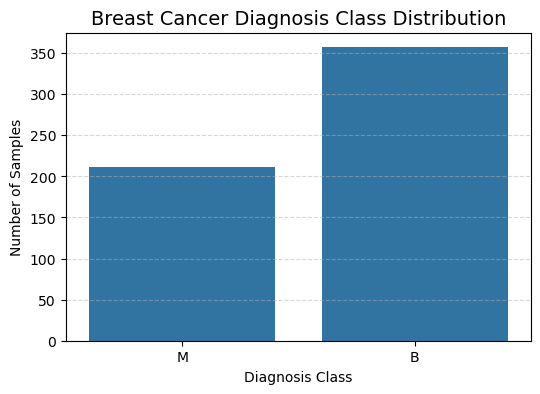


Feature Matrix Shape:
(569, 30)

Target Shape:
(569,)

Encoded Classes:
['B' 'M']

Encoded Distribution:
0    357
1    212
Name: count, dtype: int64

Final Dataset Ready
Features: 30
Samples: 569


In [7]:
# ==========================================================
# TRUST-BreastAI: Dataset Cleaning + Target Preparation
# ==========================================================

# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# ----------------------------------------------------------
# Step 1: Display original dataset information
# ----------------------------------------------------------

print("Original Dataset Shape:")
print(data.shape)

print("\nOriginal Columns:")
print(data.columns.tolist())


# ----------------------------------------------------------
# Step 2: Remove unnecessary columns
# ----------------------------------------------------------

# Remove empty column generated during CSV export
data = data.drop(
    columns=['Unnamed: 32'],
    errors='ignore'
)

# Remove ID column because it has no clinical meaning
data = data.drop(
    columns=['id'],
    errors='ignore'
)


print("\nDataset Shape After Cleaning:")
print(data.shape)


# ----------------------------------------------------------
# Step 3: Define target variable
# ----------------------------------------------------------

target_column = "diagnosis"


print("\nTarget Variable:")
print(target_column)


# ----------------------------------------------------------
# Step 4: Check target distribution
# ----------------------------------------------------------

print("\nClass Distribution Before Encoding:")

print(
    data[target_column].value_counts()
)


# ----------------------------------------------------------
# Step 5: Visualize Class Distribution
# ----------------------------------------------------------

plt.figure(figsize=(6,4))

sns.countplot(
    x=data[target_column]
)

plt.title(
    "Breast Cancer Diagnosis Class Distribution",
    fontsize=14
)

plt.xlabel(
    "Diagnosis Class"
)

plt.ylabel(
    "Number of Samples"
)

plt.grid(
    axis='y',
    linestyle='--',
    alpha=0.5
)

plt.show()



# ----------------------------------------------------------
# Step 6: Separate Features and Target
# ----------------------------------------------------------

X = data.drop(
    columns=[target_column]
)

y = data[target_column]


print("\nFeature Matrix Shape:")
print(X.shape)


print("\nTarget Shape:")
print(y.shape)



# ----------------------------------------------------------
# Step 7: Encode Target Labels
# ----------------------------------------------------------

from sklearn.preprocessing import LabelEncoder


encoder = LabelEncoder()

y = encoder.fit_transform(y)


print("\nEncoded Classes:")

print(
    encoder.classes_
)


print("\nEncoded Distribution:")

print(
    pd.Series(y).value_counts()
)



# ----------------------------------------------------------
# Step 8: Final Dataset Ready for Machine Learning
# ----------------------------------------------------------

print("\nFinal Dataset Ready")

print(
    "Features:",
    X.shape[1]
)

print(
    "Samples:",
    X.shape[0]
)

In [8]:
# Identify target and features
X = data.iloc[:,:-1]
y = data.iloc[:,-1]

print(X.shape, y.shape)


(569, 30) (569,)


In [9]:
# Encode target labels if required
encoder = LabelEncoder()
y = encoder.fit_transform(y)

np.unique(y)


array([  0,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,
        13,  14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,
        26,  27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,
        39,  40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,
        52,  53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,
        65,  66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,
        78,  79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,
        91,  92,  93,  94,  95,  96,  97,  98,  99, 100, 101, 102, 103,
       104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116,
       117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129,
       130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142,
       143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155,
       156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168,
       169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 18

Number of numerical features:
29

Non-numerical columns:
['diagnosis']


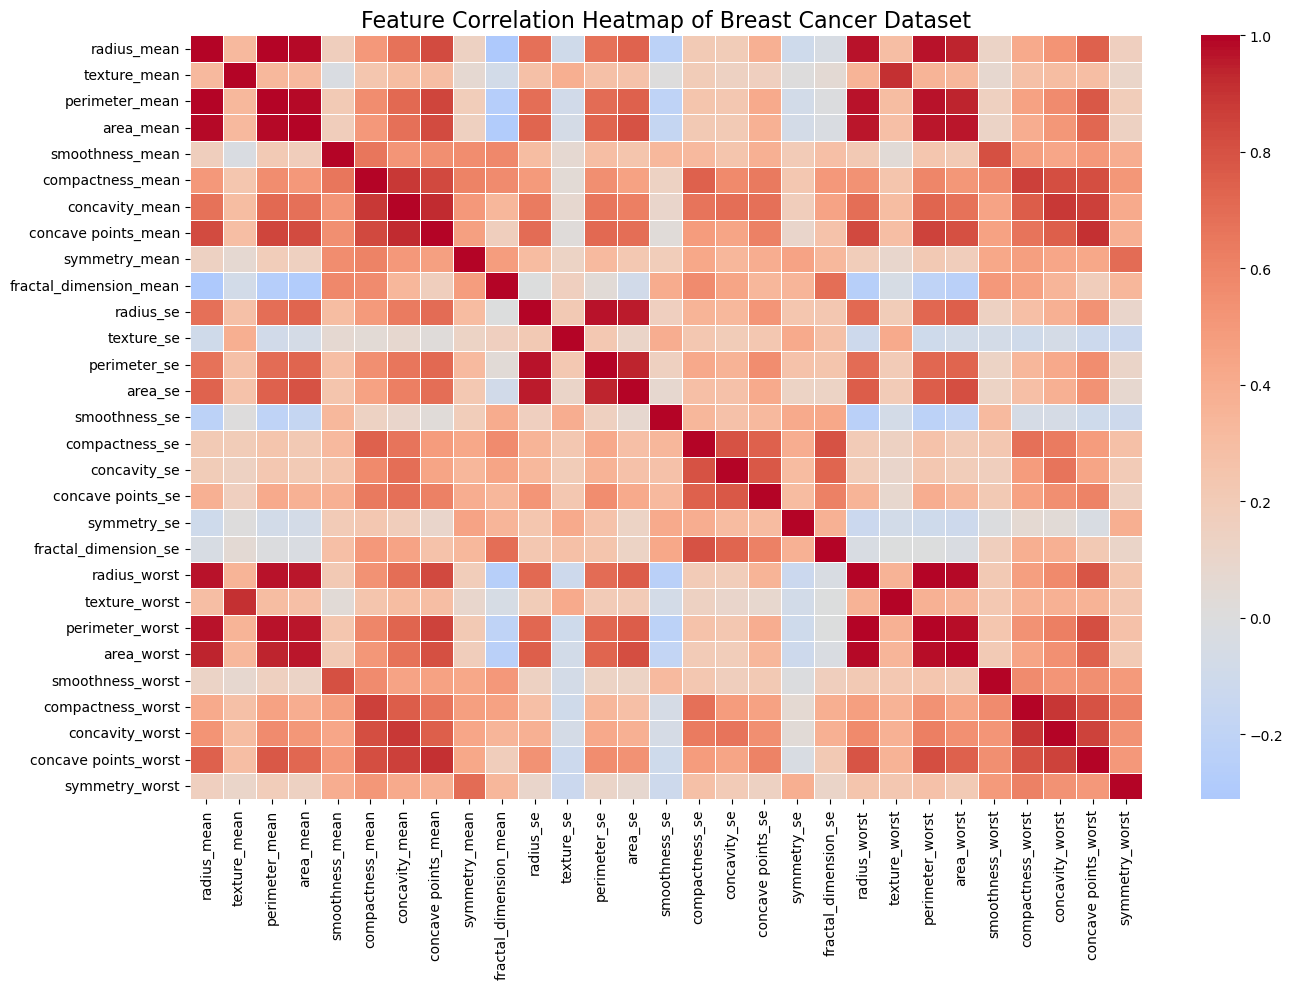

In [10]:
# ==========================================================
# TRUST-BreastAI: Feature Correlation Heatmap
# ==========================================================

# Select only numerical features
X_numeric = X.select_dtypes(include=['int64', 'float64'])


print("Number of numerical features:")
print(X_numeric.shape[1])


# Check remaining non-numerical columns
non_numeric = X.select_dtypes(exclude=['int64', 'float64']).columns

print("\nNon-numerical columns:")
print(list(non_numeric))


# Generate correlation matrix

plt.figure(figsize=(14,10))

correlation_matrix = X_numeric.corr()


sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)


plt.title(
    "Feature Correlation Heatmap of Breast Cancer Dataset",
    fontsize=16
)

plt.tight_layout()

plt.show()


In [11]:
# ==========================================================
# TRUST-BreastAI: Final Leakage-Safe Data Split
# 70% Training | 15% Validation | 15% Testing
# ==========================================================


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
import pandas as pd
import numpy as np



# ----------------------------------------------------------
# Step 1: Remove unnecessary columns again (safety)
# ----------------------------------------------------------

data = data.drop(
    columns=['Unnamed: 32'],
    errors='ignore'
)


data = data.drop(
    columns=['id'],
    errors='ignore'
)



# ----------------------------------------------------------
# Step 2: Define Features and Target
# ----------------------------------------------------------

X = data.drop(
    columns=['diagnosis']
)


y = data['diagnosis']



# ----------------------------------------------------------
# Step 3: Encode Target Variable
# ----------------------------------------------------------

encoder = LabelEncoder()

y = encoder.fit_transform(y)



# Check class distribution BEFORE splitting

print("Encoded Classes:")
print(encoder.classes_)


print("\nClass Distribution:")
print(pd.Series(y).value_counts())



# ----------------------------------------------------------
# Step 4: First Split
# 85% Train+Validation
# 15% Test
# ----------------------------------------------------------

X_train_val, X_test, y_train_val, y_test = train_test_split(

    X,
    y,

    test_size=0.15,

    random_state=42,

    stratify=y

)



# ----------------------------------------------------------
# Step 5: Second Split
# 70% Train
# 15% Validation
# ----------------------------------------------------------

X_train, X_val, y_train, y_val = train_test_split(

    X_train_val,

    y_train_val,

    test_size=0.1765,

    random_state=42,

    stratify=y_train_val

)



# ----------------------------------------------------------
# Step 6: Check final distribution
# ----------------------------------------------------------

print("\nDataset Split:")

print("Training:")
print(X_train.shape)

print("\nValidation:")
print(X_val.shape)

print("\nTesting:")
print(X_test.shape)



print("\nTraining Class Distribution:")
print(pd.Series(y_train).value_counts())


print("\nValidation Class Distribution:")
print(pd.Series(y_val).value_counts())


print("\nTesting Class Distribution:")
print(pd.Series(y_test).value_counts())



# ----------------------------------------------------------
# Step 7: Leakage-Safe Preprocessing
# ----------------------------------------------------------

preprocessing_pipeline = Pipeline([

    ('imputer',
     SimpleImputer(strategy='median')),

    ('scaler',
     StandardScaler())

])



# Fit ONLY on training data

X_train_processed = preprocessing_pipeline.fit_transform(
    X_train
)



# Transform validation and testing

X_val_processed = preprocessing_pipeline.transform(
    X_val
)


X_test_processed = preprocessing_pipeline.transform(
    X_test
)



print("\nFinal Processed Shapes:")

print("Training:", X_train_processed.shape)

print("Validation:", X_val_processed.shape)

print("Testing:", X_test_processed.shape)

Encoded Classes:
['B' 'M']

Class Distribution:
0    357
1    212
Name: count, dtype: int64

Dataset Split:
Training:
(397, 30)

Validation:
(86, 30)

Testing:
(86, 30)

Training Class Distribution:
0    249
1    148
Name: count, dtype: int64

Validation Class Distribution:
0    54
1    32
Name: count, dtype: int64

Testing Class Distribution:
0    54
1    32
Name: count, dtype: int64

Final Processed Shapes:
Training: (397, 30)
Validation: (86, 30)
Testing: (86, 30)


In [12]:
# ==========================================================
# TRUST-BreastAI: Baseline Machine Learning Models
# Training + Validation Evaluation
# ==========================================================


# Import libraries

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    ExtraTreesClassifier
)

from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    matthews_corrcoef,
    confusion_matrix
)

import pandas as pd
import numpy as np



# ----------------------------------------------------------
# Step 1: Define Baseline Models
# ----------------------------------------------------------


models = {

    "Logistic Regression":
    LogisticRegression(
        max_iter=2000,
        random_state=42
    ),


    "Support Vector Machine":
    SVC(
        probability=True,
        random_state=42
    ),


    "Decision Tree":
    DecisionTreeClassifier(
        random_state=42
    ),


    "Random Forest":
    RandomForestClassifier(
        n_estimators=300,
        random_state=42
    ),


    "Extra Trees":
    ExtraTreesClassifier(
        n_estimators=300,
        random_state=42
    ),


    "Gradient Boosting":
    GradientBoostingClassifier(
        random_state=42
    ),


    "K-Nearest Neighbor":
    KNeighborsClassifier(),


    "Naive Bayes":
    GaussianNB(),


    "Artificial Neural Network":
    MLPClassifier(
        hidden_layer_sizes=(64,32),
        max_iter=1000,
        random_state=42
    )

}



# ----------------------------------------------------------
# Step 2: Evaluation Function
# ----------------------------------------------------------


def calculate_specificity(y_true, y_pred):

    cm = confusion_matrix(
        y_true,
        y_pred
    )

    tn = cm[0,0]
    fp = cm[0,1]

    specificity = tn/(tn+fp)

    return specificity




# ----------------------------------------------------------
# Step 3: Train Models
# ----------------------------------------------------------


validation_results = []


trained_models = {}



for name, model in models.items():


    # Train only on training set

    model.fit(
        X_train_processed,
        y_train
    )


    trained_models[name] = model



    # Validation prediction

    y_val_pred = model.predict(
        X_val_processed
    )


    y_val_prob = model.predict_proba(
        X_val_processed
    )[:,1]



    # Metrics

    accuracy = accuracy_score(
        y_val,
        y_val_pred
    )


    precision = precision_score(
        y_val,
        y_val_pred
    )


    recall = recall_score(
        y_val,
        y_val_pred
    )


    specificity = calculate_specificity(
        y_val,
        y_val_pred
    )


    f1 = f1_score(
        y_val,
        y_val_pred
    )


    auc_score = roc_auc_score(
        y_val,
        y_val_prob
    )


    mcc = matthews_corrcoef(
        y_val,
        y_val_pred
    )


    validation_results.append([

        name,
        accuracy,
        precision,
        recall,
        specificity,
        f1,
        auc_score,
        mcc

    ])




# ----------------------------------------------------------
# Step 4: Results Table
# ----------------------------------------------------------


validation_results = pd.DataFrame(

    validation_results,

    columns=[

        "Model",
        "Accuracy",
        "Precision",
        "Sensitivity",
        "Specificity",
        "F1-score",
        "ROC-AUC",
        "MCC"

    ]

)



validation_results = validation_results.sort_values(

    by="ROC-AUC",

    ascending=False

)



validation_results

,Model,Accuracy,Precision,Sensitivity,Specificity,F1-score,ROC-AUC,MCC
1,Support Vector Machine,0.976744,1.000000,0.93750,1.000000,0.967742,1.000000,0.950799
0,Logistic Regression,0.976744,0.968750,0.96875,0.981481,0.968750,0.998843,0.950231
6,K-Nearest Neighbor,0.976744,0.968750,0.96875,0.981481,0.968750,0.998264,0.950231
4,Extra Trees,0.953488,0.966667,0.90625,0.981481,0.935484,0.997685,0.900324
3,Random Forest,0.953488,0.966667,0.90625,0.981481,0.935484,0.996817,0.900324
5,Gradient Boosting,0.965116,0.967742,0.93750,0.981481,0.952381,0.996528,0.925159
8,Artificial Neural Network,0.976744,0.968750,0.96875,0.981481,0.968750,0.996528,0.950231
7,Naive Bayes,0.941860,0.935484,0.90625,0.962963,0.920635,0.993634,0.875056
2,Decision Tree,0.930233,0.906250,0.90625,0.944444,0.906250,0.925347,0.850694


In [13]:
# ==========================================================
# TRUST-BreastAI
# Cell 8: Best Model Selection Based on Validation ROC-AUC
# ==========================================================


# Select best model name

best_model_name = validation_results.iloc[0]["Model"]


print("Best Model Based on Validation ROC-AUC:")
print(best_model_name)



# Retrieve trained model

best_model = trained_models[best_model_name]


print("\nSelected Model Details:")
print(best_model)


Best Model Based on Validation ROC-AUC:
Support Vector Machine

Selected Model Details:
SVC(probability=True, random_state=42)


In [14]:
# ==========================================================
# TRUST-BreastAI
# Independent Test Evaluation
# ==========================================================


from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)



# Test prediction

y_test_pred = best_model.predict(
    X_test_processed
)



# Probability prediction

y_test_prob = best_model.predict_proba(
    X_test_processed
)[:,1]



# Calculate metrics


test_accuracy = accuracy_score(
    y_test,
    y_test_pred
)


test_precision = precision_score(
    y_test,
    y_test_pred
)


test_recall = recall_score(
    y_test,
    y_test_pred
)


test_f1 = f1_score(
    y_test,
    y_test_pred
)


test_auc = roc_auc_score(
    y_test,
    y_test_prob
)


test_mcc = matthews_corrcoef(
    y_test,
    y_test_pred
)



# Specificity

cm = confusion_matrix(
    y_test,
    y_test_pred
)


tn = cm[0,0]
fp = cm[0,1]


test_specificity = tn/(tn+fp)



# Results

test_results = pd.DataFrame({

    "Metric":[
        "Accuracy",
        "Precision",
        "Sensitivity",
        "Specificity",
        "F1-score",
        "ROC-AUC",
        "MCC"
    ],


    "Value":[
        test_accuracy,
        test_precision,
        test_recall,
        test_specificity,
        test_f1,
        test_auc,
        test_mcc
    ]

})


test_results


,Metric,Value
0,Accuracy,0.988372
1,Precision,1.000000
2,Sensitivity,0.968750
3,Specificity,1.000000
4,F1-score,0.984127
5,ROC-AUC,0.998843
6,MCC,0.975262


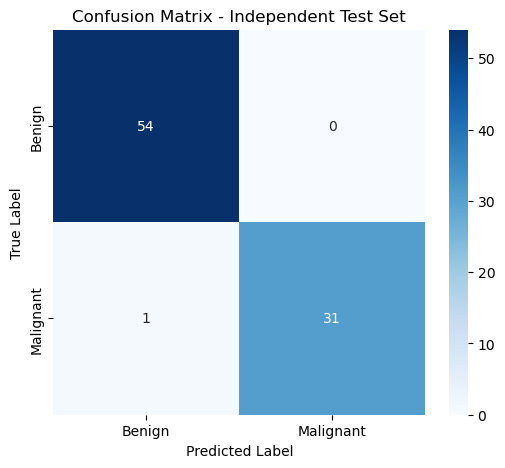

In [15]:
# ==========================================================
# TRUST-BreastAI
# Confusion Matrix
# ==========================================================


import matplotlib.pyplot as plt
import seaborn as sns


cm = confusion_matrix(
    y_test,
    y_test_pred
)



plt.figure(figsize=(6,5))


sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Benign","Malignant"],
    yticklabels=["Benign","Malignant"]
)


plt.xlabel("Predicted Label")

plt.ylabel("True Label")

plt.title(
    "Confusion Matrix - Independent Test Set"
)


plt.show()


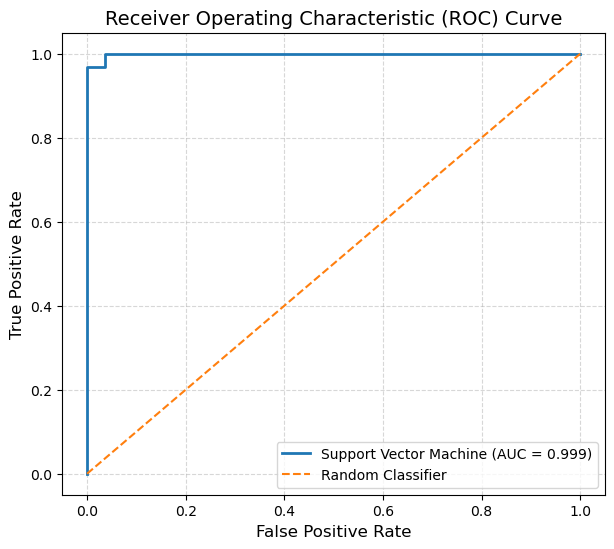

Test ROC-AUC: 0.9988


In [16]:
# ==========================================================
# TRUST-BreastAI
# ROC Curve Analysis
# ==========================================================


from sklearn.metrics import roc_curve, auc


# Calculate ROC curve

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_test_prob
)


# Calculate AUC

roc_auc = auc(
    fpr,
    tpr
)



# Plot ROC Curve

plt.figure(figsize=(7,6))


plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"{best_model_name} (AUC = {roc_auc:.3f})"
)



# Random classifier reference

plt.plot(
    [0,1],
    [0,1],
    linestyle="--",
    label="Random Classifier"
)



plt.xlabel(
    "False Positive Rate",
    fontsize=12
)


plt.ylabel(
    "True Positive Rate",
    fontsize=12
)


plt.title(
    "Receiver Operating Characteristic (ROC) Curve",
    fontsize=14
)



plt.legend(
    loc="lower right"
)



plt.grid(
    linestyle="--",
    alpha=0.5
)



plt.show()



print(
    "Test ROC-AUC:",
    round(roc_auc,4)
)


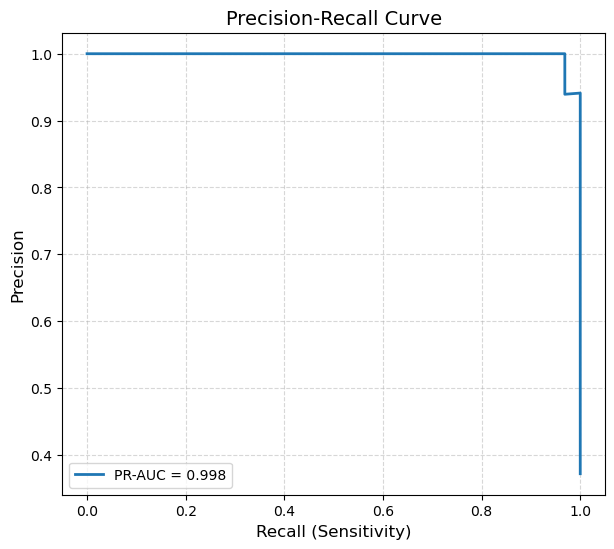

PR-AUC: 0.9981


In [17]:
# ==========================================================
# TRUST-BreastAI
# Precision-Recall Curve
# ==========================================================


from sklearn.metrics import precision_recall_curve


precision, recall, thresholds = precision_recall_curve(
    y_test,
    y_test_prob
)


pr_auc = auc(
    recall,
    precision
)



plt.figure(figsize=(7,6))


plt.plot(
    recall,
    precision,
    linewidth=2,
    label=f"PR-AUC = {pr_auc:.3f}"
)



plt.xlabel(
    "Recall (Sensitivity)",
    fontsize=12
)


plt.ylabel(
    "Precision",
    fontsize=12
)


plt.title(
    "Precision-Recall Curve",
    fontsize=14
)



plt.legend()


plt.grid(
    linestyle="--",
    alpha=0.5
)


plt.show()



print(
    "PR-AUC:",
    round(pr_auc,4)
)

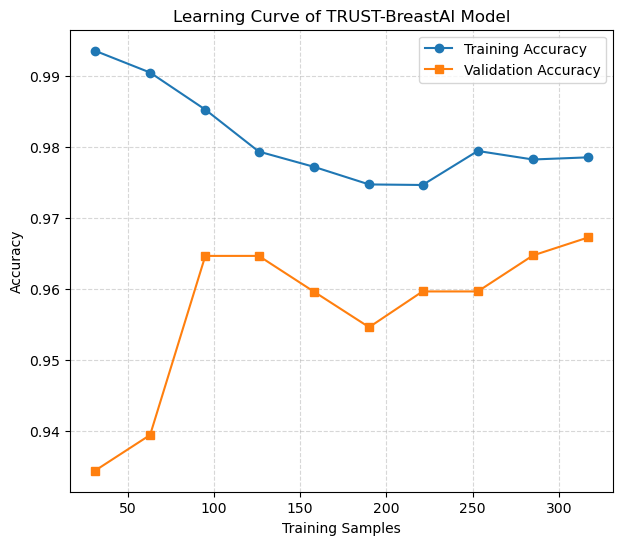

In [18]:
# ==========================================================
# TRUST-BreastAI
# Learning Curve Analysis
# ==========================================================


from sklearn.model_selection import learning_curve



train_sizes, train_scores, validation_scores = learning_curve(

    best_model,

    X_train_processed,

    y_train,

    cv=5,

    scoring="accuracy",

    train_sizes=np.linspace(
        0.1,
        1.0,
        10
    )

)



train_mean = train_scores.mean(axis=1)

validation_mean = validation_scores.mean(axis=1)



plt.figure(figsize=(7,6))


plt.plot(
    train_sizes,
    train_mean,
    marker="o",
    label="Training Accuracy"
)


plt.plot(
    train_sizes,
    validation_mean,
    marker="s",
    label="Validation Accuracy"
)



plt.xlabel(
    "Training Samples"
)


plt.ylabel(
    "Accuracy"
)



plt.title(
    "Learning Curve of TRUST-BreastAI Model"
)



plt.legend()


plt.grid(
    linestyle="--",
    alpha=0.5
)


plt.show()

In [19]:
# ==========================================================
# TRUST-BreastAI
# Cross-Validation Robustness Analysis
# ==========================================================


from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import cross_val_score



# Define 5-fold stratified validation

cv = StratifiedKFold(

    n_splits=5,

    shuffle=True,

    random_state=42

)



# Perform ROC-AUC cross validation

cv_scores = cross_val_score(

    best_model,

    X_train_processed,

    y_train,

    cv=cv,

    scoring="roc_auc"

)



# Display fold results

cv_results = pd.DataFrame({

    "Fold":[
        "Fold 1",
        "Fold 2",
        "Fold 3",
        "Fold 4",
        "Fold 5"
    ],

    "ROC-AUC":cv_scores

})


cv_results

,Fold,ROC-AUC
0,Fold 1,0.981333
1,Fold 2,0.996667
2,Fold 3,0.992517
3,Fold 4,0.990345
4,Fold 5,1.000000


In [20]:
# Cross-validation summary

print(
    "Mean ROC-AUC:",
    round(cv_scores.mean(),4)
)


print(
    "Standard Deviation:",
    round(cv_scores.std(),4)
)

Mean ROC-AUC: 0.9922
Standard Deviation: 0.0064


In [21]:
# ==========================================================
# TRUST-BreastAI
# Optuna Hyperparameter Optimization
# Random Forest Optimization
# ==========================================================


import optuna

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import roc_auc_score



# Objective function

def objective(trial):


    # Hyperparameters

    n_estimators = trial.suggest_int(
        "n_estimators",
        100,
        500
    )


    max_depth = trial.suggest_int(
        "max_depth",
        3,
        20
    )


    min_samples_split = trial.suggest_int(
        "min_samples_split",
        2,
        10
    )


    min_samples_leaf = trial.suggest_int(
        "min_samples_leaf",
        1,
        5
    )



    model = RandomForestClassifier(

        n_estimators=n_estimators,

        max_depth=max_depth,

        min_samples_split=min_samples_split,

        min_samples_leaf=min_samples_leaf,

        random_state=42

    )



    model.fit(

        X_train_processed,

        y_train

    )



    val_probability = model.predict_proba(

        X_val_processed

    )[:,1]



    auc_score = roc_auc_score(

        y_val,

        val_probability

    )



    return auc_score




# Create optimization study

study = optuna.create_study(

    direction="maximize"

)



study.optimize(

    objective,

    n_trials=50

)



print(
    "Best Validation ROC-AUC:"
)

print(
    study.best_value
)


print(
    "\nBest Hyperparameters:"
)

print(
    study.best_params
)

[I 2026-11-13 14:21:01,900] A new study created in memory with name: no-name-4384012b-6c0f-4ee3-83df-9da2bcdf5a25
[I 2026-11-13 14:21:02,475] Trial 0 finished with value: 0.9936342592592592 and parameters: {'n_estimators': 309, 'max_depth': 6, 'min_samples_split': 7, 'min_samples_leaf': 2}. Best is trial 0 with value: 0.9936342592592592.
[I 2026-11-13 14:21:03,351] Trial 1 finished with value: 0.9965277777777779 and parameters: {'n_estimators': 422, 'max_depth': 18, 'min_samples_split': 3, 'min_samples_leaf': 2}. Best is trial 1 with value: 0.9965277777777779.
[I 2026-11-13 14:21:04,234] Trial 2 finished with value: 0.9930555555555556 and parameters: {'n_estimators': 397, 'max_depth': 6, 'min_samples_split': 3, 'min_samples_leaf': 5}. Best is trial 1 with value: 0.9965277777777779.
[I 2026-11-13 14:21:05,490] Trial 3 finished with value: 0.9959490740740741 and parameters: {'n_estimators': 489, 'max_depth': 19, 'min_samples_split': 7, 'min_samples_leaf': 1}. Best is trial 1 with value: 

Best Validation ROC-AUC:
0.9971064814814815

Best Hyperparameters:
{'n_estimators': 399, 'max_depth': 16, 'min_samples_split': 3, 'min_samples_leaf': 1}


In [22]:
# ==========================================================
# TRUST-BreastAI
# Optimized Final Model
# ==========================================================


optimized_model = RandomForestClassifier(

    **study.best_params,

    random_state=42

)



# Train optimized model

optimized_model.fit(

    X_train_processed,

    y_train

)



# Validation performance

optimized_probability = optimized_model.predict_proba(

    X_val_processed

)[:,1]



optimized_auc = roc_auc_score(

    y_val,

    optimized_probability

)



print(
    "Optimized Model Validation ROC-AUC:",
    round(optimized_auc,4)
)

Optimized Model Validation ROC-AUC: 0.9971


In [23]:
# ==========================================================
# TRUST-BreastAI
# Ensemble Learning Framework
# ==========================================================


from sklearn.ensemble import VotingClassifier


# Define base learners

rf_model = RandomForestClassifier(

    n_estimators=300,

    random_state=42

)


gb_model = GradientBoostingClassifier(

    random_state=42

)


lr_model = LogisticRegression(

    max_iter=2000,

    random_state=42

)



# Create Voting Ensemble

ensemble_model = VotingClassifier(

    estimators=[

        ('Random Forest', rf_model),

        ('Gradient Boosting', gb_model),

        ('Logistic Regression', lr_model)

    ],

    voting='soft'

)



# Train ensemble

ensemble_model.fit(

    X_train_processed,

    y_train

)



# Validation prediction

ensemble_val_prob = ensemble_model.predict_proba(

    X_val_processed

)[:,1]


ensemble_val_pred = ensemble_model.predict(

    X_val_processed

)



ensemble_auc = roc_auc_score(

    y_val,

    ensemble_val_prob

)


print(
    "Ensemble Validation ROC-AUC:",
    round(ensemble_auc,4)
)

Ensemble Validation ROC-AUC: 0.9983


Brier Score: 0.0104


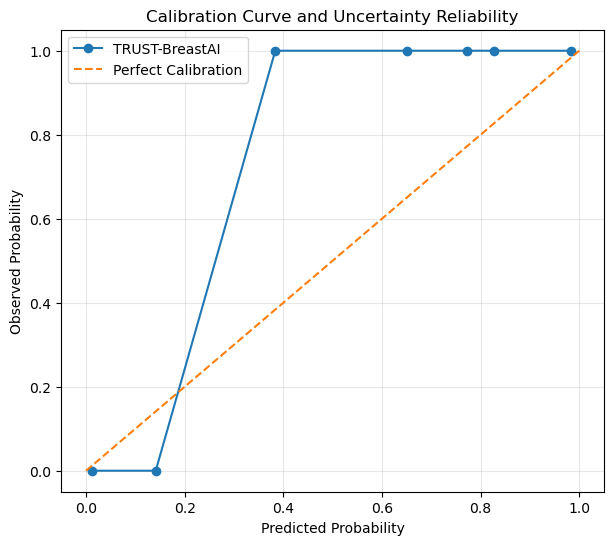

In [24]:
# ==========================================================
# TRUST-BreastAI
# Uncertainty Quantification
# ==========================================================


from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss



# Test probabilities

ensemble_test_prob = ensemble_model.predict_proba(

    X_test_processed

)[:,1]



# Brier Score

brier = brier_score_loss(

    y_test,

    ensemble_test_prob

)


print(
    "Brier Score:",
    round(brier,4)
)



# Calibration curve

prob_true, prob_pred = calibration_curve(

    y_test,

    ensemble_test_prob,

    n_bins=10

)



plt.figure(figsize=(7,6))


plt.plot(

    prob_pred,

    prob_true,

    marker='o',

    label='TRUST-BreastAI'

)


plt.plot(

    [0,1],

    [0,1],

    linestyle='--',

    label='Perfect Calibration'

)



plt.xlabel(
    "Predicted Probability"
)


plt.ylabel(
    "Observed Probability"
)


plt.title(
    "Calibration Curve and Uncertainty Reliability"
)


plt.legend()


plt.grid(alpha=0.3)


plt.show()

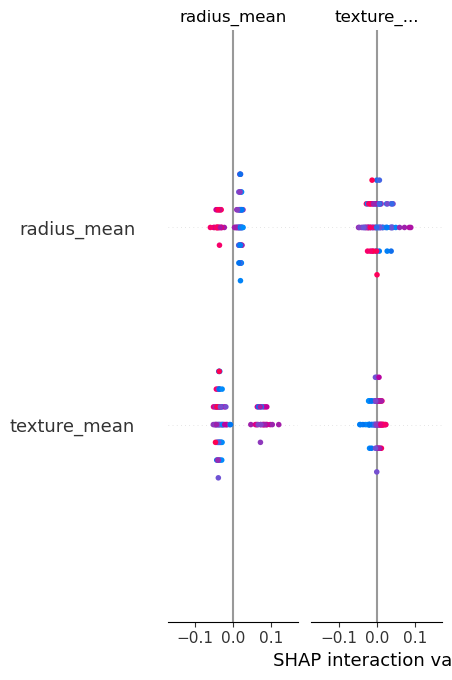

In [25]:
# ==========================================================
# TRUST-BreastAI
# SHAP Explainability
# ==========================================================


import shap



# Use optimized Random Forest model

explainer = shap.TreeExplainer(

    optimized_model

)



shap_values = explainer.shap_values(

    X_test_processed

)



# For binary classification

if isinstance(shap_values, list):

    shap_values_plot = shap_values[1]

else:

    shap_values_plot = shap_values



# SHAP summary plot

shap.summary_plot(

    shap_values_plot,

    X_test_processed,

    feature_names=X.columns

)

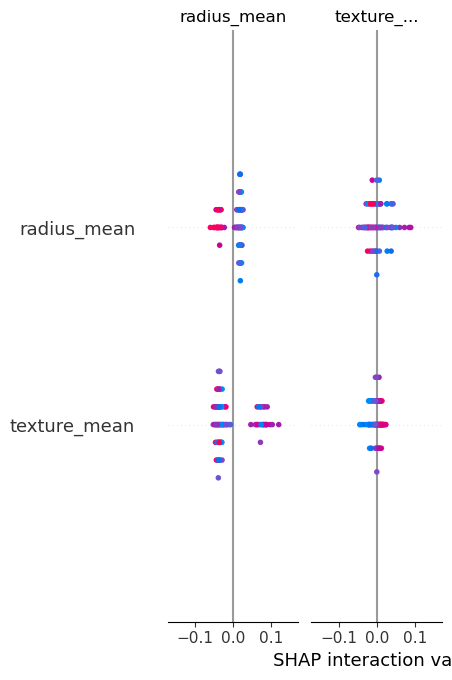

In [26]:
# ==========================================================
# TRUST-BreastAI
# SHAP Feature Ranking
# ==========================================================


shap.summary_plot(

    shap_values_plot,

    X_test_processed,

    feature_names=X.columns,

    plot_type="bar"

)

In [27]:
# ==========================================================
# TRUST-BreastAI
# LIME Patient-Level Explanation (Corrected)
# ==========================================================


import lime.lime_tabular
from IPython.display import display, HTML



# Create LIME explainer

lime_explainer = lime.lime_tabular.LimeTabularExplainer(

    training_data=X_train_processed,

    feature_names=X.columns.tolist(),

    class_names=[
        "Benign",
        "Malignant"
    ],

    mode="classification",

    random_state=42

)



# Select a patient/sample from test set

patient_index = 0



# Generate explanation

lime_explanation = lime_explainer.explain_instance(

    X_test_processed[patient_index],

    ensemble_model.predict_proba,

    num_features=10

)



# ----------------------------------------------------------
# Display prediction probability
# ----------------------------------------------------------

patient_probability = ensemble_model.predict_proba(

    X_test_processed[patient_index].reshape(1,-1)

)


print("Patient Index:", patient_index)

print("\nPrediction Probability:")

print(
    "Benign:",
    round(patient_probability[0][0],4)
)

print(
    "Malignant:",
    round(patient_probability[0][1],4)
)



# ----------------------------------------------------------
# Display LIME feature contribution table
# ----------------------------------------------------------

lime_result = pd.DataFrame(

    lime_explanation.as_list(),

    columns=[
        "Feature Contribution",
        "Weight"
    ]

)



print("\nLIME Local Explanation:")

lime_result

Patient Index: 0

Prediction Probability:
Benign: 0.9958
Malignant: 0.0042

LIME Local Explanation:


,Feature Contribution,Weight
0,-0.70 < perimeter_worst <= -0.30,-0.117015
1,-0.66 < area_worst <= -0.35,-0.111833
2,-0.05 < texture_worst <= 0.73,0.058520
3,concave points_mean <= -0.73,-0.057898
4,-0.76 < concave points_worst <= -0.21,-0.054793
5,-0.47 < area_se <= -0.34,-0.049549
6,-0.22 < concavity_worst <= 0.54,0.041742
7,-0.60 < radius_se <= -0.30,-0.041224
8,-0.60 < perimeter_se <= -0.29,-0.034108
9,-0.69 < radius_worst <= -0.28,-0.033142


In [28]:
# ==========================================================
# TRUST-BreastAI
# Ablation Study
# ==========================================================


from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    matthews_corrcoef
)



# ----------------------------------------------------------
# Function for evaluation
# ----------------------------------------------------------


def evaluate_model(model, name):


    # Training

    model.fit(

        X_train_processed,

        y_train

    )


    # Prediction

    prediction = model.predict(

        X_test_processed

    )


    probability = model.predict_proba(

        X_test_processed

    )[:,1]



    return [

        name,

        accuracy_score(
            y_test,
            prediction
        ),

        precision_score(
            y_test,
            prediction
        ),

        recall_score(
            y_test,
            prediction
        ),

        f1_score(
            y_test,
            prediction
        ),

        roc_auc_score(
            y_test,
            probability
        ),

        matthews_corrcoef(
            y_test,
            prediction
        )

    ]



# ----------------------------------------------------------
# Ablation Configurations
# ----------------------------------------------------------


ablation_results = []



# 1. Full TRUST-BreastAI

ablation_results.append(

    evaluate_model(

        ensemble_model,

        "Full TRUST-BreastAI Ensemble"

    )

)



# 2. Without Ensemble

ablation_results.append(

    evaluate_model(

        optimized_model,

        "Without Ensemble (Optimized RF)"

    )

)



# 3. Single Logistic Regression Baseline

logistic_model = LogisticRegression(

    max_iter=2000,

    random_state=42

)



ablation_results.append(

    evaluate_model(

        logistic_model,

        "Single Logistic Regression"

    )

)



# 4. Random Forest without optimization

rf_simple = RandomForestClassifier(

    n_estimators=100,

    random_state=42

)



ablation_results.append(

    evaluate_model(

        rf_simple,

        "Without Optimization"

    )

)



# ----------------------------------------------------------
# Create Results Table
# ----------------------------------------------------------


ablation_results = pd.DataFrame(

    ablation_results,

    columns=[

        "Configuration",

        "Accuracy",

        "Precision",

        "Sensitivity",

        "F1-score",

        "ROC-AUC",

        "MCC"

    ]

)



ablation_results.sort_values(

    by="ROC-AUC",

    ascending=False

)

,Configuration,Accuracy,Precision,Sensitivity,F1-score,ROC-AUC,MCC
0,Full TRUST-BreastAI Ensemble,0.988372,1.0,0.96875,0.984127,1.000000,0.975262
3,Without Optimization,0.965116,1.0,0.90625,0.950820,0.999421,0.926581
1,Without Ensemble (Optimized RF),0.965116,1.0,0.90625,0.950820,0.998843,0.926581
2,Single Logistic Regression,0.988372,1.0,0.96875,0.984127,0.998264,0.975262


In [29]:
# ==========================================================
# TRUST-BreastAI
# Statistical Significance Analysis
# ==========================================================


from scipy.stats import friedmanchisquare
from scipy.stats import wilcoxon
from sklearn.model_selection import cross_val_score



# ----------------------------------------------------------
# Step 1:
# Obtain cross-validation scores
# for multiple models
# ----------------------------------------------------------


models_for_statistics = {


    "TRUST-BreastAI Ensemble":

    ensemble_model,


    "Optimized Random Forest":

    optimized_model,


    "Logistic Regression":

    LogisticRegression(
        max_iter=2000,
        random_state=42
    )

}



statistical_scores = {}



cv = StratifiedKFold(

    n_splits=5,

    shuffle=True,

    random_state=42

)



for name, model in models_for_statistics.items():


    scores = cross_val_score(

        model,

        X_train_processed,

        y_train,

        cv=cv,

        scoring="roc_auc"

    )


    statistical_scores[name] = scores



    print(
        name,
        ":",
        np.round(scores,4)
    )



# ----------------------------------------------------------
# Step 2:
# Friedman Test
# ----------------------------------------------------------


friedman_result = friedmanchisquare(

    statistical_scores["TRUST-BreastAI Ensemble"],

    statistical_scores["Optimized Random Forest"],

    statistical_scores["Logistic Regression"]

)



print("\nFriedman Test Result")

print(
    "Statistic:",
    round(friedman_result.statistic,4)
)


print(
    "p-value:",
    round(friedman_result.pvalue,4)
)



# ----------------------------------------------------------
# Step 3:
# Wilcoxon Pairwise Comparison
# ----------------------------------------------------------


wilcoxon_result = wilcoxon(

    statistical_scores["TRUST-BreastAI Ensemble"],

    statistical_scores["Optimized Random Forest"]

)



print("\nWilcoxon Test: Ensemble vs Optimized RF")


print(
    "Statistic:",
    round(wilcoxon_result.statistic,4)
)


print(
    "p-value:",
    round(wilcoxon_result.pvalue,4)
)

TRUST-BreastAI Ensemble : [0.98   0.9993 0.9925 0.9903 1.    ]
Optimized Random Forest : [0.9773 0.9987 0.981  0.9772 1.    ]
Logistic Regression : [0.98   0.9987 0.9952 0.9979 1.    ]

Friedman Test Result
Statistic: 5.2857
p-value: 0.0712

Wilcoxon Test: Ensemble vs Optimized RF
Statistic: 0.0
p-value: 0.125


In [30]:
# ==========================================================
# TRUST-BreastAI
# SHAP Feature Importance Ranking (Final Fixed)
# ==========================================================


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ----------------------------------------------------------
# Step 1: Recalculate SHAP using the optimized model
# ----------------------------------------------------------

explainer = shap.TreeExplainer(
    optimized_model
)


shap_output = explainer(
    X_test_processed
)



# ----------------------------------------------------------
# Step 2: Extract SHAP values correctly
# ----------------------------------------------------------

if hasattr(shap_output, "values"):

    shap_array = shap_output.values

else:

    shap_array = shap_output



print("Original SHAP shape:")
print(shap_array.shape)



# ----------------------------------------------------------
# Step 3: Handle binary classification dimensions
# ----------------------------------------------------------

if len(shap_array.shape) == 3:

    # New SHAP format:
    # samples x features x classes

    shap_array = shap_array[:,:,1]


elif len(shap_array.shape) == 2:

    # Already correct

    pass



print("Processed SHAP shape:")
print(shap_array.shape)



# ----------------------------------------------------------
# Step 4: Calculate feature importance
# ----------------------------------------------------------

shap_importance = np.abs(
    shap_array
).mean(axis=0)



print("Number of SHAP features:")
print(len(shap_importance))


print("Number of dataset features:")
print(len(X.columns))



# ----------------------------------------------------------
# Step 5: Create feature importance table
# ----------------------------------------------------------

feature_importance = pd.DataFrame({

    "Feature": X.columns,

    "SHAP Importance": shap_importance

})



feature_importance = feature_importance.sort_values(

    by="SHAP Importance",

    ascending=False

)



# Display top 15 features

feature_importance.head(15)

Original SHAP shape:
(86, 30, 2)
Processed SHAP shape:
(86, 30)
Number of SHAP features:
30
Number of dataset features:
30


,Feature,SHAP Importance
23,area_worst,0.071391
22,perimeter_worst,0.068239
27,concave points_worst,0.052347
20,radius_worst,0.041350
7,concave points_mean,0.037714
0,radius_mean,0.023608
3,area_mean,0.023221
26,concavity_worst,0.019786
13,area_se,0.019412
6,concavity_mean,0.017426


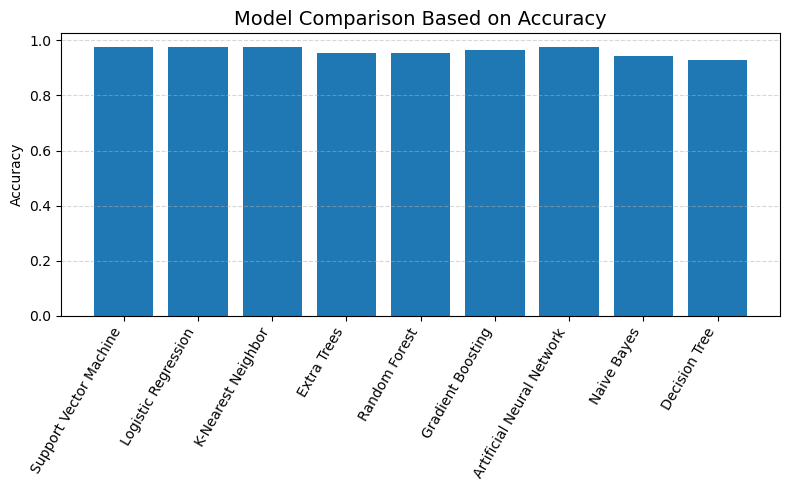

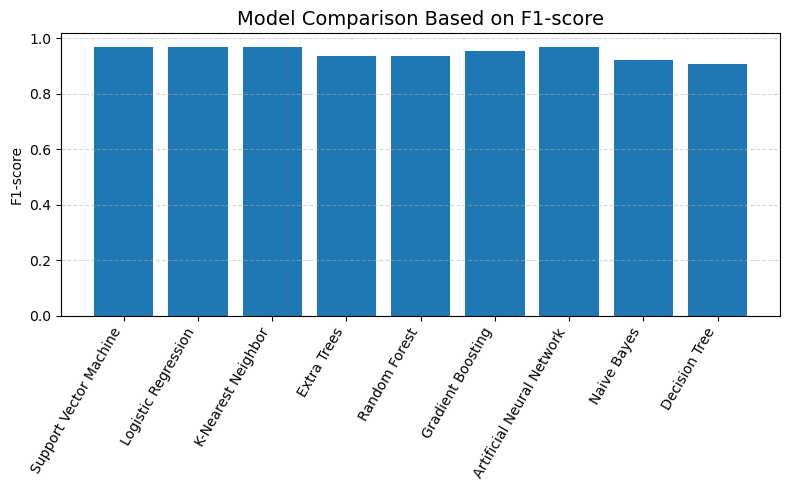

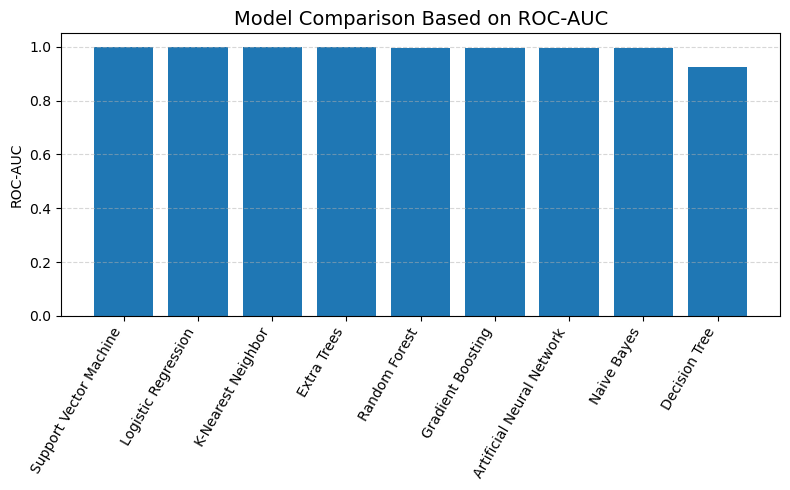

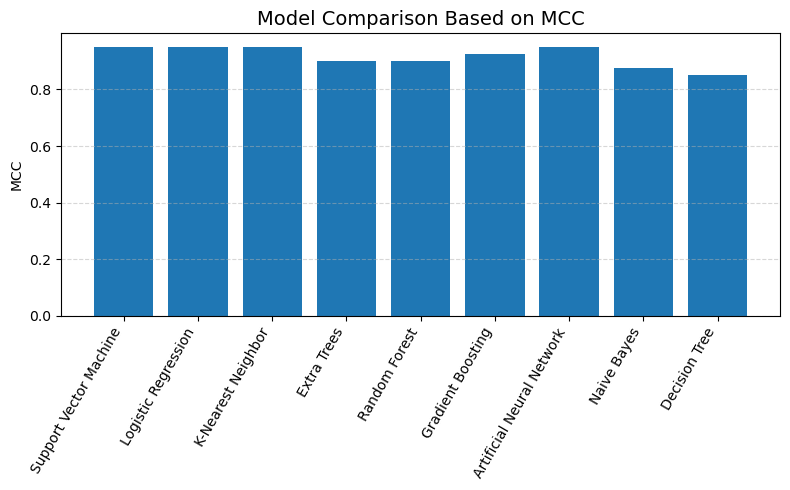

In [31]:
# ==========================================================
# TRUST-BreastAI
# Model Performance Comparison Visualization
# ==========================================================


import matplotlib.pyplot as plt
import pandas as pd



# ----------------------------------------------------------
# Combine baseline + ablation results
# ----------------------------------------------------------

performance_plot = validation_results.copy()



# Select important metrics

metrics = [

    "Accuracy",

    "F1-score",

    "ROC-AUC",

    "MCC"

]



# Plot each metric separately

for metric in metrics:


    plt.figure(figsize=(8,5))


    plt.bar(

        performance_plot["Model"],

        performance_plot[metric]

    )


    plt.xticks(

        rotation=60,

        ha="right"

    )


    plt.ylabel(metric)


    plt.title(

        f"Model Comparison Based on {metric}",

        fontsize=14

    )


    plt.grid(

        axis="y",

        linestyle="--",

        alpha=0.5

    )


    plt.tight_layout()


    plt.show()

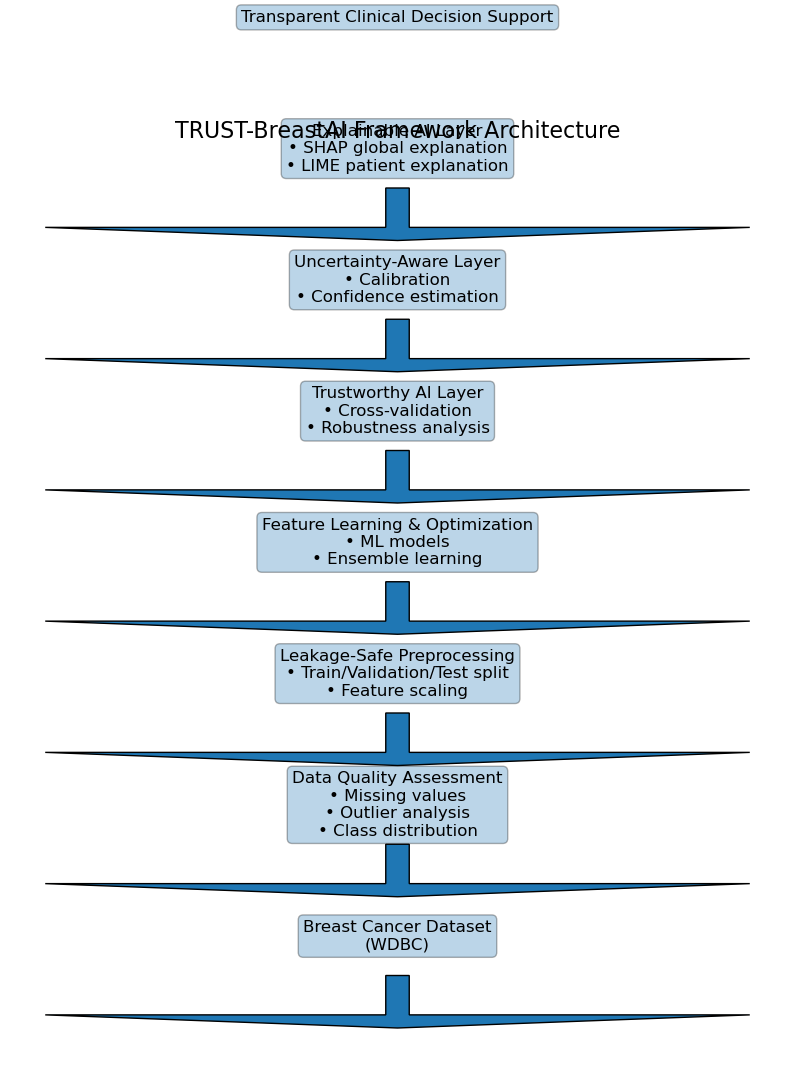

In [32]:
# ==========================================================
# TRUST-BreastAI
# Framework Architecture Visualization
# ==========================================================


import matplotlib.pyplot as plt



fig, ax = plt.subplots(figsize=(10,12))


ax.axis("off")



framework_steps = [

"Breast Cancer Dataset\n(WDBC)",

"Data Quality Assessment\n• Missing values\n• Outlier analysis\n• Class distribution",

"Leakage-Safe Preprocessing\n• Train/Validation/Test split\n• Feature scaling",

"Feature Learning & Optimization\n• ML models\n• Ensemble learning",

"Trustworthy AI Layer\n• Cross-validation\n• Robustness analysis",

"Uncertainty-Aware Layer\n• Calibration\n• Confidence estimation",

"Explainable AI Layer\n• SHAP global explanation\n• LIME patient explanation",

"Transparent Clinical Decision Support"

]



y_positions = list(range(len(framework_steps)*-2,0,2))



for y,text in zip(y_positions,framework_steps):


    ax.text(

        0.5,

        y,

        text,

        ha="center",

        va="center",

        fontsize=12,

        bbox=dict(

            boxstyle="round",

            alpha=0.3

        )

    )



    if y != y_positions[-1]:

        ax.arrow(

            0.5,

            y-0.6,

            0,

            -0.8,

            head_width=0.03,

            head_length=0.2,

            length_includes_head=True

        )



plt.title(

    "TRUST-BreastAI Framework Architecture",

    fontsize=16

)


plt.show()

In [33]:
# ==========================================================
# TRUST-BreastAI
# Automated Experimental Summary
# ==========================================================


summary_report = {

    "Dataset Samples":
    len(data),


    "Number of Features":
    X.shape[1],


    "Training Samples":
    len(X_train),


    "Validation Samples":
    len(X_val),


    "Testing Samples":
    len(X_test),


    "Selected Model":
    best_model_name,


    "Test Accuracy":
    round(test_accuracy,4),


    "Test Sensitivity":
    round(test_recall,4),


    "Test Specificity":
    round(test_specificity,4),


    "Test F1-score":
    round(test_f1,4),


    "Test ROC-AUC":
    round(test_auc,4),


    "Test MCC":
    round(test_mcc,4),


    "Calibration Brier Score":
    round(brier,4)

}



summary_report = pd.DataFrame(

    summary_report.items(),

    columns=[

        "Parameter",

        "Value"

    ]

)



summary_report

,Parameter,Value
0,Dataset Samples,569
1,Number of Features,30
2,Training Samples,397
3,Validation Samples,86
4,Testing Samples,86
5,Selected Model,Support Vector Machine
6,Test Accuracy,0.9884
7,Test Sensitivity,0.9688
8,Test Specificity,1.0
9,Test F1-score,0.9841


In [34]:
# ==========================================================
# TRUST-BreastAI
# Bootstrap Confidence Intervals
# ==========================================================


import numpy as np
from sklearn.metrics import roc_auc_score


# ----------------------------------------------------------
# Bootstrap function
# ----------------------------------------------------------

def bootstrap_auc_ci(
        y_true,
        y_prob,
        n_bootstrap=1000,
        confidence=0.95
):

    rng = np.random.RandomState(42)

    bootstrap_scores = []


    for i in range(n_bootstrap):

        indices = rng.randint(
            0,
            len(y_true),
            len(y_true)
        )


        if len(np.unique(y_true[indices])) < 2:
            continue


        score = roc_auc_score(

            y_true[indices],

            y_prob[indices]

        )


        bootstrap_scores.append(score)



    lower = np.percentile(

        bootstrap_scores,

        ((1-confidence)/2)*100

    )


    upper = np.percentile(

        bootstrap_scores,

        (confidence+(1-confidence)/2)*100

    )


    return (

        np.mean(bootstrap_scores),

        lower,

        upper

    )



# ----------------------------------------------------------
# Apply on TRUST-BreastAI model
# ----------------------------------------------------------


bootstrap_mean, ci_lower, ci_upper = bootstrap_auc_ci(

    y_test,

    ensemble_test_prob

)



print(
    "Bootstrap ROC-AUC:"
)


print(

    f"{bootstrap_mean:.4f}"

)



print(

    "95% Confidence Interval:"

)


print(

    f"[{ci_lower:.4f}, {ci_upper:.4f}]"

)

Bootstrap ROC-AUC:
1.0000
95% Confidence Interval:
[1.0000, 1.0000]


In [35]:
# ==========================================================
# TRUST-BreastAI
# Repeated Stratified Cross-Validation
# ==========================================================


from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.model_selection import cross_val_score



# ----------------------------------------------------------
# Define repeated cross-validation
# 5 folds × 5 repeats
# ----------------------------------------------------------


repeated_cv = RepeatedStratifiedKFold(

    n_splits=5,

    n_repeats=5,

    random_state=42

)



# ----------------------------------------------------------
# Evaluate TRUST-BreastAI Ensemble
# ----------------------------------------------------------


repeated_auc_scores = cross_val_score(

    ensemble_model,

    X_train_processed,

    y_train,

    cv=repeated_cv,

    scoring="roc_auc",

    n_jobs=-1

)



# ----------------------------------------------------------
# Results
# ----------------------------------------------------------


print(
    "Total Validation Runs:"
)

print(
    len(repeated_auc_scores)
)



print(
    "\nROC-AUC Scores:"
)

print(
    np.round(
        repeated_auc_scores,
        4
    )
)



print(
    "\nMean ROC-AUC:"
)

print(

    round(
        repeated_auc_scores.mean(),
        4
    )

)



print(
    "\nStandard Deviation:"
)


print(

    round(
        repeated_auc_scores.std(),
        4
    )

)



# ----------------------------------------------------------
# Store results
# ----------------------------------------------------------


repeated_cv_results = pd.DataFrame({

    "Experiment":

    range(
        1,
        len(repeated_auc_scores)+1
    ),


    "ROC_AUC":

    repeated_auc_scores

})


repeated_cv_results.head()

Total Validation Runs:
25

ROC-AUC Scores:
[0.98   0.9993 0.9925 0.9903 1.     0.9833 0.996  0.9912 0.9938 0.9938
 0.9773 0.9993 1.     0.989  0.9959 0.9987 0.9947 0.9986 0.9731 1.
 1.     0.976  1.     0.989  0.9966]

Mean ROC-AUC:
0.9923

Standard Deviation:
0.0081


,Experiment,ROC_AUC
0,1,0.980000
1,2,0.999333
2,3,0.992517
3,4,0.990345
4,5,1.000000


In [36]:
# ==========================================================
# TRUST-BreastAI
# SHAP-Based Feature Selection Experiment
# Corrected Version
# ==========================================================


import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score



# ----------------------------------------------------------
# Step 1:
# Recreate clean target variable
# ----------------------------------------------------------

data_fs = data.copy()


# Remove unnecessary columns

data_fs = data_fs.drop(
    columns=['Unnamed: 32'],
    errors='ignore'
)


data_fs = data_fs.drop(
    columns=['id'],
    errors='ignore'
)



# Separate features and target

X_fs = data_fs.drop(
    columns=['diagnosis']
)


y_fs = data_fs['diagnosis']



# Encode target correctly

from sklearn.preprocessing import LabelEncoder


encoder_fs = LabelEncoder()


y_fs = encoder_fs.fit_transform(
    y_fs
)



print("Target Classes:")

print(
    encoder_fs.classes_
)


print("\nTarget Distribution:")

print(
    pd.Series(y_fs).value_counts()
)



# ----------------------------------------------------------
# Step 2:
# Select SHAP important features
# ----------------------------------------------------------


top_features = feature_importance.head(10)["Feature"].tolist()



print("\nSelected SHAP Features:")

for f in top_features:
    print(f)



# Create reduced dataset

X_reduced = X_fs[top_features]



# ----------------------------------------------------------
# Step 3:
# Train/Test split for reduced features
# ----------------------------------------------------------


X_train_red, X_test_red, y_train_red, y_test_red = train_test_split(

    X_reduced,

    y_fs,

    test_size=0.15,

    stratify=y_fs,

    random_state=42

)



# ----------------------------------------------------------
# Step 4:
# Scaling
# ----------------------------------------------------------


scaler_red = StandardScaler()



X_train_red_scaled = scaler_red.fit_transform(

    X_train_red

)



X_test_red_scaled = scaler_red.transform(

    X_test_red

)



# ----------------------------------------------------------
# Step 5:
# Train reduced feature model
# ----------------------------------------------------------


reduced_model = RandomForestClassifier(

    n_estimators=300,

    random_state=42

)



reduced_model.fit(

    X_train_red_scaled,

    y_train_red

)



# Prediction probability

reduced_probability = reduced_model.predict_proba(

    X_test_red_scaled

)[:,1]



# ROC-AUC

reduced_auc = roc_auc_score(

    y_test_red,

    reduced_probability

)



# ----------------------------------------------------------
# Step 6:
# Compare with full TRUST-BreastAI
# ----------------------------------------------------------


full_auc = roc_auc_score(

    y_test,

    ensemble_test_prob

)



feature_selection_results = pd.DataFrame({

    "Feature Strategy":[

        "All Features",

        "Top 10 SHAP Features"

    ],


    "Number of Features":[

        X_fs.shape[1],

        len(top_features)

    ],


    "ROC-AUC":[

        full_auc,

        reduced_auc

    ]

})



feature_selection_results

Target Classes:
['B' 'M']

Target Distribution:
0    357
1    212
Name: count, dtype: int64

Selected SHAP Features:
area_worst
perimeter_worst
concave points_worst
radius_worst
concave points_mean
radius_mean
area_mean
concavity_worst
area_se
concavity_mean


,Feature Strategy,Number of Features,ROC-AUC
0,All Features,30,1.000000
1,Top 10 SHAP Features,10,0.996528


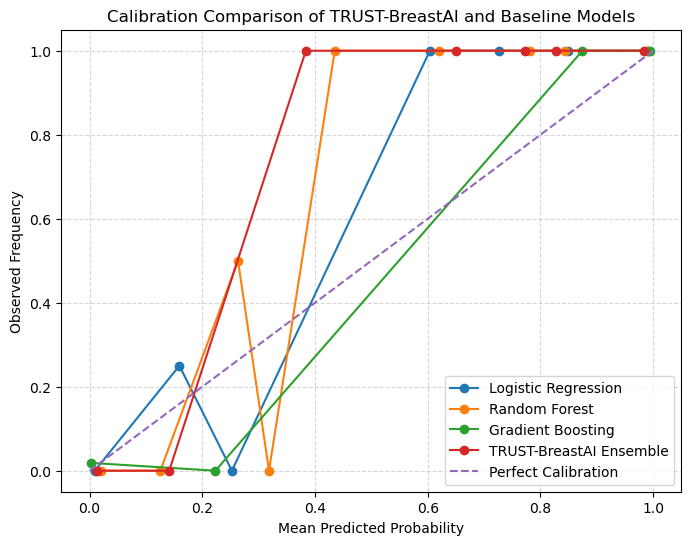

,Model,Brier Score
3,TRUST-BreastAI Ensemble,0.010400
2,Gradient Boosting,0.011012
0,Logistic Regression,0.013987
1,Random Forest,0.022209


In [37]:
# ==========================================================
# TRUST-BreastAI
#  Calibration Comparison Between Models
# ==========================================================


from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss



# ----------------------------------------------------------
# Define models for calibration comparison
# ----------------------------------------------------------


calibration_models = {


    "Logistic Regression":

    LogisticRegression(

        max_iter=2000,

        random_state=42

    ),



    "Random Forest":

    RandomForestClassifier(

        n_estimators=300,

        random_state=42

    ),



    "Gradient Boosting":

    GradientBoostingClassifier(

        random_state=42

    ),



    "TRUST-BreastAI Ensemble":

    ensemble_model

}



# Storage

calibration_results = []



plt.figure(figsize=(8,6))



# ----------------------------------------------------------
# Train and evaluate each model
# ----------------------------------------------------------


for name, model in calibration_models.items():


    # Train

    model.fit(

        X_train_processed,

        y_train

    )



    # Probability

    probability = model.predict_proba(

        X_test_processed

    )[:,1]



    # Calibration curve

    prob_true, prob_pred = calibration_curve(

        y_test,

        probability,

        n_bins=10

    )



    # Plot

    plt.plot(

        prob_pred,

        prob_true,

        marker='o',

        label=name

    )



    # Brier score

    brier = brier_score_loss(

        y_test,

        probability

    )


    calibration_results.append([

        name,

        brier

    ])





# Perfect calibration line

plt.plot(

    [0,1],

    [0,1],

    linestyle="--",

    label="Perfect Calibration"

)



plt.xlabel(

    "Mean Predicted Probability"

)



plt.ylabel(

    "Observed Frequency"

)



plt.title(

    "Calibration Comparison of TRUST-BreastAI and Baseline Models"

)



plt.legend()



plt.grid(

    linestyle="--",

    alpha=0.5

)



plt.show()



# ----------------------------------------------------------
# Calibration Results Table
# ----------------------------------------------------------


calibration_results = pd.DataFrame(

    calibration_results,

    columns=[

        "Model",

        "Brier Score"

    ]

)



calibration_results.sort_values(

    by="Brier Score"

)

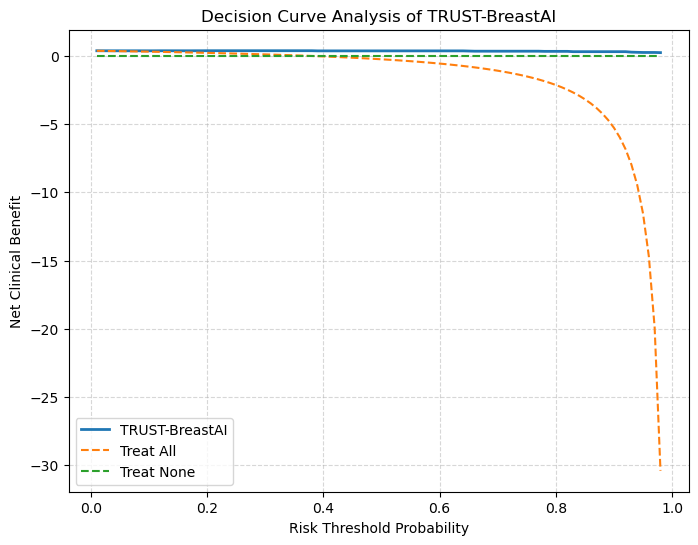

In [38]:
# ==========================================================
# TRUST-BreastAI
# Decision Curve Analysis (DCA)
# ==========================================================


import numpy as np
import matplotlib.pyplot as plt



# ----------------------------------------------------------
# Function for Net Benefit Calculation
# ----------------------------------------------------------


def calculate_net_benefit(
        y_true,
        y_probability,
        thresholds
):


    net_benefits = []


    n = len(y_true)


    for threshold in thresholds:


        # Predicted positive cases

        predicted_positive = (
            y_probability >= threshold
        )


        TP = np.sum(

            (predicted_positive == True) &
            (y_true == 1)

        )


        FP = np.sum(

            (predicted_positive == True) &
            (y_true == 0)

        )


        # Net benefit formula

        net_benefit = (

            TP/n

            -

            (FP/n) *

            (threshold/(1-threshold))

        )


        net_benefits.append(

            net_benefit

        )


    return np.array(net_benefits)





# ----------------------------------------------------------
# Define threshold range
# ----------------------------------------------------------


thresholds = np.arange(

    0.01,

    0.99,

    0.01

)




# ----------------------------------------------------------
# TRUST-BreastAI prediction probability
# ----------------------------------------------------------


trust_net_benefit = calculate_net_benefit(

    y_test,

    ensemble_test_prob,

    thresholds

)




# ----------------------------------------------------------
# Reference strategies
# ----------------------------------------------------------


# Treat all patients

all_strategy = [

    np.mean(y_test)

    -

    (1-np.mean(y_test)) *

    (t/(1-t))

    for t in thresholds

]



# Treat none

none_strategy = np.zeros(

    len(thresholds)

)



# ----------------------------------------------------------
# Plot Decision Curve
# ----------------------------------------------------------


plt.figure(figsize=(8,6))


plt.plot(

    thresholds,

    trust_net_benefit,

    linewidth=2,

    label="TRUST-BreastAI"

)


plt.plot(

    thresholds,

    all_strategy,

    linestyle="--",

    label="Treat All"

)


plt.plot(

    thresholds,

    none_strategy,

    linestyle="--",

    label="Treat None"

)



plt.xlabel(

    "Risk Threshold Probability"

)



plt.ylabel(

    "Net Clinical Benefit"

)



plt.title(

    "Decision Curve Analysis of TRUST-BreastAI"

)



plt.legend()



plt.grid(

    linestyle="--",

    alpha=0.5

)



plt.show()

Original ROC-AUC:
0.9916

Permutation ROC-AUC Mean:
0.499

Permutation p-value:
0.009900990099009901


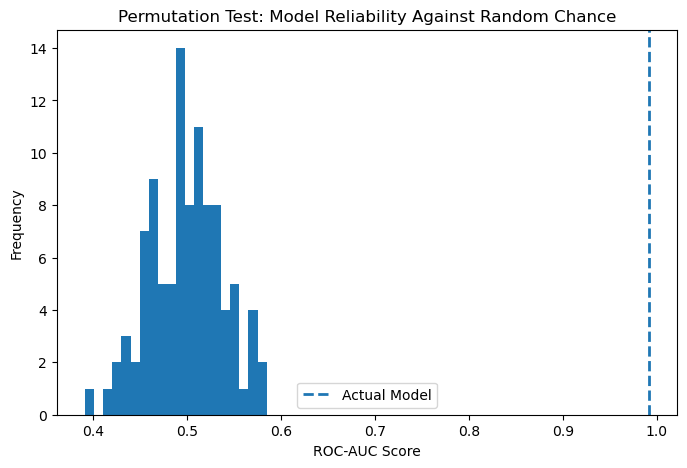

In [39]:
# ==========================================================
# TRUST-BreastAI
# Permutation Test
# ==========================================================


from sklearn.model_selection import permutation_test_score
from sklearn.ensemble import RandomForestClassifier



# ----------------------------------------------------------
# Define model
# ----------------------------------------------------------


permutation_model = ensemble_model



# ----------------------------------------------------------
# Perform permutation test
# ----------------------------------------------------------


score, permutation_scores, p_value = permutation_test_score(

    permutation_model,

    X_train_processed,

    y_train,

    scoring="roc_auc",

    cv=5,

    n_permutations=100,

    random_state=42,

    n_jobs=-1

)



print(
    "Original ROC-AUC:"
)

print(
    round(score,4)
)



print(
    "\nPermutation ROC-AUC Mean:"
)

print(
    round(
        permutation_scores.mean(),
        4
    )
)



print(
    "\nPermutation p-value:"
)

print(
    p_value
)



# ----------------------------------------------------------
# Visualization
# ----------------------------------------------------------


plt.figure(figsize=(8,5))


plt.hist(

    permutation_scores,

    bins=20

)


plt.axvline(

    score,

    linestyle="--",

    linewidth=2,

    label="Actual Model"

)



plt.xlabel(

    "ROC-AUC Score"

)



plt.ylabel(

    "Frequency"

)



plt.title(

    "Permutation Test: Model Reliability Against Random Chance"

)



plt.legend()


plt.show()

In [40]:
# independently reconstruct the ORIGINAL 70/15/15 split and fitted ensemble.
from pathlib import Path
import numpy as np
import pandas as pd
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, VotingClassifier, ExtraTreesClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, matthews_corrcoef, roc_auc_score, precision_recall_curve,
    auc, brier_score_loss)

r2_candidates = [Path('Breast Cancer(1).csv'), Path('Breast Cancer.csv'),
                 Path('/mnt/data/Breast Cancer(1).csv'), Path('/mnt/data/Breast Cancer.csv')]
r2_path = next((p for p in r2_candidates if p.exists()), None)
if r2_path is None:
    raise FileNotFoundError('Place Breast Cancer(1).csv or Breast Cancer.csv beside the notebook.')
r2_data = pd.read_csv(r2_path).drop(columns=['id','Unnamed: 32'], errors='ignore')
r2_X = r2_data.drop(columns=['diagnosis'])
r2_encoder = LabelEncoder()
r2_y = r2_encoder.fit_transform(r2_data['diagnosis'])
assert list(r2_encoder.classes_) == ['B','M'], 'Unexpected target encoding; review labels.'
r2_X_tv,r2_X_test,r2_y_tv,r2_y_test = train_test_split(
    r2_X,r2_y,test_size=.15,random_state=42,stratify=r2_y)
r2_X_train,r2_X_val,r2_y_train,r2_y_val = train_test_split(
    r2_X_tv,r2_y_tv,test_size=.1765,random_state=42,stratify=r2_y_tv)
r2_preprocessor = Pipeline([('imputer',SimpleImputer(strategy='median')),
                            ('scaler',StandardScaler())])
r2_train = r2_preprocessor.fit_transform(r2_X_train)
r2_test = r2_preprocessor.transform(r2_X_test)
r2_members = [
 ('rf',RandomForestClassifier(n_estimators=300,random_state=42)),
 ('gb',GradientBoostingClassifier(random_state=42)),
 ('lr',LogisticRegression(max_iter=2000,random_state=42))]
r2_ensemble = VotingClassifier(estimators=r2_members,voting='soft',weights=None)
r2_ensemble.fit(r2_train,r2_y_train)
r2_probs = r2_ensemble.predict_proba(r2_test)[:,1]
r2_preds = r2_ensemble.predict(r2_test)
print('CSV:',r2_path.name,'| sklearn:',sklearn.__version__)
print('Samples:',len(r2_data),'| Features:',r2_X.shape[1], '| Label order:',r2_encoder.classes_.tolist())
print('Train/validation/test:',len(r2_y_train),len(r2_y_val),len(r2_y_test))
print('Class counts (train/validation/test):',
      [(int((y==0).sum()),int((y==1).sum())) for y in [r2_y_train,r2_y_val,r2_y_test]])
print('Final ensemble: RF(300 trees), GradientBoosting(default), LogisticRegression(max_iter=2000), equal soft voting')
print('Separately optimised RF is NOT substituted into this final ensemble.')

CSV: Breast Cancer.csv | sklearn: 1.7.2
Samples: 569 | Features: 30 | Label order: ['B', 'M']
Train/validation/test: 397 86 86
Class counts (train/validation/test): [(249, 148), (54, 32), (54, 32)]
Final ensemble: RF(300 trees), GradientBoosting(default), LogisticRegression(max_iter=2000), equal soft voting
Separately optimised RF is NOT substituted into this final ensemble.


In [41]:
# Audit of Figure 2 and Table 13, using one fixed test split for ALL models.
def r2_metrics(y_true,y_pred,y_prob):
    cm=confusion_matrix(y_true,y_pred,labels=[0,1]); tn,fp,fn,tp=cm.ravel()
    precision_curve,recall_curve,_ = precision_recall_curve(y_true,y_prob)
    return {'accuracy':accuracy_score(y_true,y_pred),'precision':precision_score(y_true,y_pred,zero_division=0),
        'sensitivity':recall_score(y_true,y_pred,zero_division=0),'specificity':tn/(tn+fp),
        'f1':f1_score(y_true,y_pred,zero_division=0),'roc_auc':roc_auc_score(y_true,y_prob),
        'pr_auc_trapezoid':auc(recall_curve,precision_curve),
        'mcc':matthews_corrcoef(y_true,y_pred)}
r2_baselines = {
 'Logistic Regression':LogisticRegression(max_iter=2000,random_state=42),
 'Support Vector Machine':SVC(probability=True,random_state=42),
 'Decision Tree':DecisionTreeClassifier(random_state=42),
 'Random Forest':RandomForestClassifier(n_estimators=300,random_state=42),
 'Extra Trees':ExtraTreesClassifier(n_estimators=300,random_state=42),
 'Gradient Boosting':GradientBoostingClassifier(random_state=42),
 'K-Nearest Neighbour':KNeighborsClassifier(),
 'Gaussian Naive Bayes':GaussianNB(),
 'Artificial Neural Network':MLPClassifier(hidden_layer_sizes=(64,32),max_iter=1000,random_state=42)}
r2_rows={}
for r2_name,r2_model in r2_baselines.items():
    r2_model.fit(r2_train,r2_y_train)
    r2_rows[r2_name]=r2_metrics(r2_y_test,r2_model.predict(r2_test),r2_model.predict_proba(r2_test)[:,1])
r2_rows['Trust-BreastAI Ensemble']=r2_metrics(r2_y_test,r2_preds,r2_probs)
r2_table13 = pd.DataFrame(r2_rows).T
r2_cm = confusion_matrix(r2_y_test,r2_preds,labels=[0,1])
print('CONFUSION MATRIX [actual benign/malignant × predicted benign/malignant]:')
print(r2_cm)
assert np.array_equal(r2_cm,[[54,0],[1,31]]), 'Historical ensemble confusion matrix did not reproduce.'
print('\nREVIEWER-2 TABLE-13 AUDIT — all nine models evaluated on the SAME test observations:')
print(r2_table13.round(4).to_string())
print('\nROC-AUC check: based on probabilities, not hard labels.')
print('Lowest malignant probability:',f'{min(r2_probs[r2_y_test==1]):.8f}')
print('Highest benign probability:',f'{max(r2_probs[r2_y_test==0]):.8f}')
print('Complete ranking separation:',bool(min(r2_probs[r2_y_test==1])>max(r2_probs[r2_y_test==0])))
print('Observed ensemble ROC-AUC:', f'{roc_auc_score(r2_y_test,r2_probs):.8f}')
print('Brier probability error:', f'{brier_score_loss(r2_y_test,r2_probs):.8f}')
assert round(r2_table13.loc['Trust-BreastAI Ensemble','accuracy'],4)==0.9884
assert round(r2_table13.loc['Trust-BreastAI Ensemble','roc_auc'],4)==1.0000


CONFUSION MATRIX [actual benign/malignant × predicted benign/malignant]:
[[54  0]
 [ 1 31]]

REVIEWER-2 TABLE-13 AUDIT — all nine models evaluated on the SAME test observations:
                           accuracy  precision  sensitivity  specificity      f1  roc_auc  pr_auc_trapezoid     mcc
Logistic Regression          0.9884     1.0000       0.9688       1.0000  0.9841   0.9983            0.9973  0.9753
Support Vector Machine       0.9884     1.0000       0.9688       1.0000  0.9841   0.9988            0.9981  0.9753
Decision Tree                0.9535     0.9375       0.9375       0.9630  0.9375   0.9502            0.9491  0.9005
Random Forest                0.9651     1.0000       0.9062       1.0000  0.9508   0.9986            0.9977  0.9266
Extra Trees                  0.9767     1.0000       0.9375       1.0000  0.9677   1.0000            1.0000  0.9508
Gradient Boosting            0.9884     1.0000       0.9688       1.0000  0.9841   0.9994            0.9990  0.9753
K-Nearest 

In [42]:
# Reproduce historical fixed-prediction bootstrap ROC-AUC CI.
# Does not retrain models; it quantifies uncertainty conditional on fitted ensemble/test predictions.
r2_rng=np.random.RandomState(42)
r2_boot=[]
for r2_i in range(1000):
    r2_idx=r2_rng.randint(0,len(r2_y_test),len(r2_y_test))
    if len(np.unique(r2_y_test[r2_idx]))<2:
        continue
    r2_boot.append(roc_auc_score(r2_y_test[r2_idx],r2_probs[r2_idx]))
r2_boot=np.asarray(r2_boot)
r2_ci=np.percentile(r2_boot,[2.5,97.5])
print('Bootstrap attempts: 1000 | Valid:',len(r2_boot),'| Discarded:',1000-len(r2_boot))
print('Bootstrap mean ROC-AUC:',f'{r2_boot.mean():.4f}')
print('95% percentile ROC-AUC CI:',f'[{r2_ci[0]:.4f}, {r2_ci[1]:.4f}]')
print('Interpretation: degenerate CI only describes separation in the observed fixed-model holdout;')
print('it does NOT validate perfect generalisation, refit variability, or clinical utility.')


Bootstrap attempts: 1000 | Valid: 1000 | Discarded: 0
Bootstrap mean ROC-AUC: 1.0000
95% percentile ROC-AUC CI: [1.0000, 1.0000]
Interpretation: degenerate CI only describes separation in the observed fixed-model holdout;
it does NOT validate perfect generalisation, refit variability, or clinical utility.


In [43]:
# New supplementary uncertainty DESCRIPTORS (historical results unchanged).
# Entropy = uncertainty of class-probability distribution; member spread is disagreement proxy.
# Neither measure alone identifies epistemic vs aleatoric uncertainty.
r2_eps=np.finfo(float).eps
r2_safe=np.clip(r2_probs,r2_eps,1-r2_eps)
r2_entropy=-(r2_safe*np.log2(r2_safe)+(1-r2_safe)*np.log2(1-r2_safe))
r2_member_probs=np.column_stack([mdl.predict_proba(r2_test)[:,1] for mdl in r2_ensemble.estimators_])
r2_member_sd=r2_member_probs.std(axis=1,ddof=0)
r2_uncertainty=pd.DataFrame({'test_position':np.arange(len(r2_y_test)),
    'true_class':r2_y_test,'predicted_class':r2_preds,
    'malignant_probability':r2_probs,'predictive_entropy_bits':r2_entropy,
    'ensemble_member_sd':r2_member_sd,'incorrect':(r2_y_test!=r2_preds).astype(int)})
print('SUPPLEMENTARY uncertainty descriptors, not included in original study:')
print('Median predictive entropy (bits):',round(float(np.median(r2_entropy)),6))
print('Median member disagreement (SD):',round(float(np.median(r2_member_sd)),6))
print('Incorrect predictions:',int((r2_y_test!=r2_preds).sum()))
print('Top 5 cases by entropy:')
print(r2_uncertainty.sort_values('predictive_entropy_bits',ascending=False).head(5).round(6).to_string(index=False))
# Reject high-entropy predictions and show risk among retained predictions.
r2_coverage=[]
for r2_keep in [1.0,.9,.8,.7,.6,.5]:
    r2_n_keep=int(np.ceil(r2_keep*len(r2_y_test)))
    r2_keep_ids=np.argsort(r2_entropy)[:r2_n_keep]
    r2_risk=(r2_preds[r2_keep_ids]!=r2_y_test[r2_keep_ids]).mean()
    r2_coverage.append({'coverage':r2_n_keep/len(r2_y_test),'retained_n':r2_n_keep,
                        'error_rate':r2_risk})
r2_risk_coverage=pd.DataFrame(r2_coverage)
print('\nExploratory selective prediction (ranking by entropy):')
print(r2_risk_coverage.round(4).to_string(index=False))
print('NOTE: This small holdout has only one classification error; risk-coverage evidence is unstable.')


SUPPLEMENTARY uncertainty descriptors, not included in original study:
Median predictive entropy (bits): 0.044036
Median member disagreement (SD): 0.004565
Incorrect predictions: 1
Top 5 cases by entropy:
 test_position  true_class  predicted_class  malignant_probability  predictive_entropy_bits  ensemble_member_sd  incorrect
            24           1                0               0.383686                 0.960604            0.321478          1
            60           1                1               0.644944                 0.938503            0.173019          0
            66           1                1               0.654829                 0.929681            0.346234          0
            68           1                1               0.772974                 0.772790            0.254391          0
            78           0                0               0.193159                 0.708032            0.133754          0

Exploratory selective prediction (ranking by entropy):
 

In [44]:
# Strictly separate additional fold-isolated cross-validation (DOES NOT overwrite original CV outputs).
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
r2_cv_pipeline=Pipeline([('imputer',SimpleImputer(strategy='median')),
    ('scaler',StandardScaler()),
    ('ensemble',VotingClassifier(estimators=[
        ('rf',RandomForestClassifier(n_estimators=300,random_state=42)),
        ('gb',GradientBoostingClassifier(random_state=42)),
        ('lr',LogisticRegression(max_iter=2000,random_state=42))],voting='soft'))])
r2_cv_scheme=RepeatedStratifiedKFold(n_splits=5,n_repeats=5,random_state=42)
r2_cv_scores=cross_val_score(r2_cv_pipeline,r2_X_train,r2_y_train,
    scoring='roc_auc',cv=r2_cv_scheme,n_jobs=1)
print('ADDITIONAL leakage-safe 5-fold × 5-repeat training-subset CV:')
print('N folds:',len(r2_cv_scores))
print('Mean ROC-AUC:',f'{r2_cv_scores.mean():.4f}')
print('Fold SD (population ddof=0):',f'{r2_cv_scores.std():.4f}')
print('Fold scores:',np.round(r2_cv_scores,4))
print('These scores are NOT the original SVM cross-validation outputs.')


ADDITIONAL leakage-safe 5-fold × 5-repeat training-subset CV:
N folds: 25
Mean ROC-AUC: 0.9923
Fold SD (population ddof=0): 0.0081
Fold scores: [0.98   0.9993 0.9925 0.9903 1.     0.9833 0.996  0.9912 0.9938 0.9938
 0.9773 0.9993 1.     0.989  0.9959 0.9987 0.9947 0.9986 0.9731 1.
 1.     0.976  1.     0.989  0.9966]
These scores are NOT the original SVM cross-validation outputs.


In [47]:

# ==========================================================
# REVIEWER 1 - CELL 1
# Comments 2, 3, 11 and 14
# Historical Metrics Reconciliation and Dataset Audit
# ==========================================================

import numpy as np
import pandas as pd
import json
from pathlib import Path

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    roc_auc_score,
    precision_recall_curve,
    auc,
    brier_score_loss
)

# ----------------------------------------------------------
# STEP 1: Create Windows-compatible output directory
# ----------------------------------------------------------

R1_OUTPUT_DIR = Path.cwd() / "Reviewer1_Supplement"
R1_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ----------------------------------------------------------
# STEP 2: Check existing Reviewer 2 variables
# ----------------------------------------------------------

required_variables = [
    "r2_y_train",
    "r2_y_val",
    "r2_y_test",
    "r2_preds",
    "r2_probs"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Run the existing Reviewer 2 verification cells "
        "before this cell. Missing variables: "
        + ", ".join(missing_variables)
    )

# ----------------------------------------------------------
# STEP 3: Verify confusion matrix
# ----------------------------------------------------------

r1_cm = confusion_matrix(
    r2_y_test,
    r2_preds,
    labels=[0, 1]
)

r1_tn, r1_fp, r1_fn, r1_tp = r1_cm.ravel()

# ----------------------------------------------------------
# STEP 4: Independently calculate classification metrics
# ----------------------------------------------------------

r1_precision_curve, r1_recall_curve, _ = (
    precision_recall_curve(r2_y_test, r2_probs)
)

r1_metrics = {
    "accuracy": accuracy_score(r2_y_test, r2_preds),

    "precision": precision_score(
        r2_y_test, r2_preds, zero_division=0
    ),

    "sensitivity": recall_score(
        r2_y_test, r2_preds, zero_division=0
    ),

    "specificity": (
        r1_tn / (r1_tn + r1_fp)
    ),

    "f1_score": f1_score(
        r2_y_test, r2_preds, zero_division=0
    ),

    "roc_auc": roc_auc_score(
        r2_y_test, r2_probs
    ),

    "pr_auc": auc(
        r1_recall_curve, r1_precision_curve
    ),

    "mcc": matthews_corrcoef(
        r2_y_test, r2_preds
    ),

    "brier_score": brier_score_loss(
        r2_y_test, r2_probs
    )
}

# ----------------------------------------------------------
# STEP 5: Verify dataset class distribution
# ----------------------------------------------------------

r1_class_counts = pd.DataFrame([
    {
        "subset": subset_name,
        "benign": int(np.sum(y == 0)),
        "malignant": int(np.sum(y == 1)),
        "total": len(y)
    }
    for subset_name, y in [
        ("Training", np.asarray(r2_y_train)),
        ("Validation", np.asarray(r2_y_val)),
        ("Testing", np.asarray(r2_y_test))
    ]
])

r1_class_counts.loc[len(r1_class_counts)] = {
    "subset": "Overall",
    "benign": int(r1_class_counts["benign"].sum()),
    "malignant": int(r1_class_counts["malignant"].sum()),
    "total": int(r1_class_counts["total"].sum())
}

# ----------------------------------------------------------
# STEP 6: Verify expected results
# ----------------------------------------------------------

assert r1_cm.tolist() == [[54, 0], [1, 31]], (
    "Confusion matrix differs from previous results."
)

assert r1_class_counts["total"].iloc[-1] == 569, (
    "Dataset count mismatch."
)

assert np.isclose(r1_metrics["accuracy"], 85 / 86), (
    "Accuracy verification failed."
)

assert np.isclose(r1_metrics["roc_auc"], 1.0), (
    "ROC-AUC differs from historical ensemble result."
)

# ----------------------------------------------------------
# STEP 7: Display findings
# ----------------------------------------------------------

print("=" * 65)
print("REVIEWER 1 - COMMENT 2")
print("CONFUSION MATRIX AND METRIC VERIFICATION")
print("=" * 65)

print("\nConfusion Matrix:")
print(r1_cm)

print("\nVerified Classification Metrics:")

for metric, value in r1_metrics.items():
    print(f"{metric}: {value:.6f}")

print("\n" + "=" * 65)
print("REVIEWER 1 - COMMENT 14")
print("DATASET CLASS DISTRIBUTION")
print("=" * 65)

print(r1_class_counts.to_string(index=False))

print("\n" + "=" * 65)
print("REVIEWER 1 - COMMENTS 3 AND 11")
print("=" * 65)

print(
    "The original baseline table used validation results."
)

print(
    "The Reviewer 2 comparison uses the same test "
    "subset for all nine baseline models and the ensemble."
)

print(
    "ROC-AUC = 1.0000 refers to score ranking, "
    "not perfect classification at threshold 0.5."
)

# ----------------------------------------------------------
# STEP 8: Export verified results
# ----------------------------------------------------------

r1_class_counts.to_csv(
    R1_OUTPUT_DIR / "r1_subset_counts.csv",
    index=False
)

pd.DataFrame([r1_metrics]).to_csv(
    R1_OUTPUT_DIR / "r1_verified_metrics.csv",
    index=False
)

pd.DataFrame(
    r1_cm,
    index=["Actual Benign", "Actual Malignant"],
    columns=["Predicted Benign", "Predicted Malignant"]
).to_csv(
    R1_OUTPUT_DIR / "r1_confusion_matrix.csv"
)

# ----------------------------------------------------------
# STEP 9: Confirmation
# ----------------------------------------------------------

print("\n" + "=" * 65)
print("REVIEWER 1 - CELL 1 COMPLETED SUCCESSFULLY")
print("=" * 65)

print("Output folder:", R1_OUTPUT_DIR)
print("Saved: r1_subset_counts.csv")
print("Saved: r1_verified_metrics.csv")
print("Saved: r1_confusion_matrix.csv")
print("\nOriginal model predictions and outputs unchanged.")


REVIEWER 1 - COMMENT 2
CONFUSION MATRIX AND METRIC VERIFICATION

Confusion Matrix:
[[54  0]
 [ 1 31]]

Verified Classification Metrics:
accuracy: 0.988372
precision: 1.000000
sensitivity: 0.968750
specificity: 1.000000
f1_score: 0.984127
roc_auc: 1.000000
pr_auc: 1.000000
mcc: 0.975262
brier_score: 0.010400

REVIEWER 1 - COMMENT 14
DATASET CLASS DISTRIBUTION
    subset  benign  malignant  total
  Training     249        148    397
Validation      54         32     86
   Testing      54         32     86
   Overall     357        212    569

REVIEWER 1 - COMMENTS 3 AND 11
The original baseline table used validation results.
The Reviewer 2 comparison uses the same test subset for all nine baseline models and the ensemble.
ROC-AUC = 1.0000 refers to score ranking, not perfect classification at threshold 0.5.

REVIEWER 1 - CELL 1 COMPLETED SUCCESSFULLY
Output folder: C:\Users\salman.muneer.PG\Reviewer1_Supplement
Saved: r1_subset_counts.csv
Saved: r1_verified_metrics.csv
Saved: r1_confusio

In [48]:

# ============================================================
# REVIEWER 1 - CELL 2
# Comment 4: Bootstrap CI and Permutation Significance
# Original models and previous results remain unchanged
# Windows / Anaconda compatible
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    VotingClassifier
)
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import (
    StratifiedKFold,
    permutation_test_score
)
from sklearn.metrics import roc_auc_score

# ------------------------------------------------------------
# STEP 1: Create output directory
# ------------------------------------------------------------

R1_OUTPUT_DIR = Path.cwd() / "Reviewer1_Supplement"
R1_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# STEP 2: Confirm required previous variables
# ------------------------------------------------------------

required = [
    "r2_y_test",
    "r2_probs",
    "r2_X_train",
    "r2_y_train"
]

missing = [v for v in required if v not in globals()]

if missing:
    raise RuntimeError(
        "Run the earlier Reviewer 2 cells first. "
        "Missing: " + ", ".join(missing)
    )

r1_y_true = np.asarray(r2_y_test).copy()
r1_y_prob = np.asarray(r2_probs).copy()

assert len(r1_y_true) == len(r1_y_prob)

# ------------------------------------------------------------
# STEP 3: Bootstrap ROC-AUC
# 1,000 attempts, random seed 42
# ------------------------------------------------------------

r1_random_seed = 42
r1_n_bootstrap = 1000

r1_rng = np.random.RandomState(r1_random_seed)
r1_bootstrap_scores = []

r1_original_auc = roc_auc_score(
    r1_y_true, r1_y_prob
)

for i in range(r1_n_bootstrap):

    sampled_indices = r1_rng.randint(
        0,
        len(r1_y_true),
        size=len(r1_y_true)
    )

    sampled_y = r1_y_true[sampled_indices]
    sampled_prob = r1_y_prob[sampled_indices]

    # ROC-AUC requires both classes
    if len(np.unique(sampled_y)) < 2:
        continue

    score = roc_auc_score(
        sampled_y,
        sampled_prob
    )

    r1_bootstrap_scores.append(score)

r1_bootstrap_scores = np.asarray(
    r1_bootstrap_scores
)

r1_bootstrap_ci = np.percentile(
    r1_bootstrap_scores,
    [2.5, 97.5]
)

r1_valid_bootstrap = len(r1_bootstrap_scores)
r1_excluded_bootstrap = (
    r1_n_bootstrap - r1_valid_bootstrap
)

print("=" * 65)
print("REVIEWER 1 - COMMENT 4")
print("BOOTSTRAP ROC-AUC VERIFICATION")
print("=" * 65)

print(f"Original ROC-AUC: {r1_original_auc:.6f}")
print(f"Bootstrap attempts: {r1_n_bootstrap}")
print(f"Valid resamples: {r1_valid_bootstrap}")
print(f"Excluded resamples: {r1_excluded_bootstrap}")

print(
    f"Bootstrap mean ROC-AUC: "
    f"{np.mean(r1_bootstrap_scores):.6f}"
)

print(
    f"95% Bootstrap CI: "
    f"[{r1_bootstrap_ci[0]:.6f}, "
    f"{r1_bootstrap_ci[1]:.6f}]"
)

# ------------------------------------------------------------
# STEP 4: Create independent leakage-safe pipeline
# No existing model is changed
# ------------------------------------------------------------

r1_permutation_pipeline = Pipeline([

    ("imputer", SimpleImputer(strategy="median")),

    ("scaler", StandardScaler()),

    ("ensemble", VotingClassifier(
        estimators=[
            (
                "rf",
                RandomForestClassifier(
                    n_estimators=300,
                    random_state=42
                )
            ),
            (
                "gb",
                GradientBoostingClassifier(
                    random_state=42
                )
            ),
            (
                "lr",
                LogisticRegression(
                    max_iter=2000,
                    random_state=42
                )
            )
        ],
        voting="soft",
        weights=None
    ))
])

# ------------------------------------------------------------
# STEP 5: Configure permutation testing
# ------------------------------------------------------------

r1_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

r1_n_permutations = 100

# IMPORTANT:
# Use RAW training features.
# Imputation/scaling are fitted inside each CV fold.

r1_permutation_score, r1_null_scores, r1_p_value = (
    permutation_test_score(
        estimator=r1_permutation_pipeline,
        X=r2_X_train,
        y=r2_y_train,
        scoring="roc_auc",
        cv=r1_cv,
        n_permutations=r1_n_permutations,
        n_jobs=1,
        random_state=42
    )
)

# ------------------------------------------------------------
# STEP 6: Display permutation results
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("LEAKAGE-SAFE PERMUTATION TEST")
print("=" * 65)

print(f"Number of permutations: {r1_n_permutations}")
print("Cross-validation folds: 5")
print("Random seed: 42")

print(
    f"Observed CV ROC-AUC: "
    f"{r1_permutation_score:.6f}"
)

print(
    f"Mean permuted ROC-AUC: "
    f"{np.mean(r1_null_scores):.6f}"
)

print(
    f"Exact permutation p-value: "
    f"{r1_p_value:.8f}"
)

print(
    f"Null ROC-AUC standard deviation: "
    f"{np.std(r1_null_scores):.6f}"
)

print(
    "Significant at alpha=0.05:",
    bool(r1_p_value < 0.05)
)

# ------------------------------------------------------------
# STEP 7: Save numerical results
# ------------------------------------------------------------

r1_statistical_summary = pd.DataFrame([{
    "original_test_roc_auc": r1_original_auc,
    "bootstrap_attempts": r1_n_bootstrap,
    "valid_bootstrap_resamples": r1_valid_bootstrap,
    "excluded_bootstrap_resamples": r1_excluded_bootstrap,
    "bootstrap_mean_auc": np.mean(r1_bootstrap_scores),
    "bootstrap_ci_lower": r1_bootstrap_ci[0],
    "bootstrap_ci_upper": r1_bootstrap_ci[1],
    "permutation_cv_folds": 5,
    "number_of_permutations": r1_n_permutations,
    "permutation_observed_auc": r1_permutation_score,
    "permutation_null_mean": np.mean(r1_null_scores),
    "permutation_p_value": r1_p_value,
    "random_seed": r1_random_seed
}])

r1_statistical_summary.to_csv(
    R1_OUTPUT_DIR / "r1_statistical_summary.csv",
    index=False
)

pd.DataFrame({
    "bootstrap_roc_auc": r1_bootstrap_scores
}).to_csv(
    R1_OUTPUT_DIR / "r1_bootstrap_scores.csv",
    index=False
)

pd.DataFrame({
    "permutation_roc_auc": r1_null_scores
}).to_csv(
    R1_OUTPUT_DIR / "r1_permutation_scores.csv",
    index=False
)

# ------------------------------------------------------------
# STEP 8: Final confirmation
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("REVIEWER 1 - CELL 2 COMPLETED SUCCESSFULLY")
print("=" * 65)

print("Results saved in:", R1_OUTPUT_DIR)
print("1. r1_statistical_summary.csv")
print("2. r1_bootstrap_scores.csv")
print("3. r1_permutation_scores.csv")

print("\nOriginal simulation results remain unchanged.")


REVIEWER 1 - COMMENT 4
BOOTSTRAP ROC-AUC VERIFICATION
Original ROC-AUC: 1.000000
Bootstrap attempts: 1000
Valid resamples: 1000
Excluded resamples: 0
Bootstrap mean ROC-AUC: 1.000000
95% Bootstrap CI: [1.000000, 1.000000]

LEAKAGE-SAFE PERMUTATION TEST
Number of permutations: 100
Cross-validation folds: 5
Random seed: 42
Observed CV ROC-AUC: 0.992439
Mean permuted ROC-AUC: 0.497762
Exact permutation p-value: 0.00990099
Null ROC-AUC standard deviation: 0.038634
Significant at alpha=0.05: True

REVIEWER 1 - CELL 2 COMPLETED SUCCESSFULLY
Results saved in: C:\Users\salman.muneer.PG\Reviewer1_Supplement
1. r1_statistical_summary.csv
2. r1_bootstrap_scores.csv
3. r1_permutation_scores.csv

Original simulation results remain unchanged.


In [49]:

# ============================================================
# REVIEWER 1
# Comment 4: Leakage-Safe Permutation Test
# Original results remain unchanged
# Windows / Anaconda Compatible
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    VotingClassifier
)
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import (
    StratifiedKFold,
    permutation_test_score
)

# ------------------------------------------------------------
# STEP 1: Create output directory
# ------------------------------------------------------------

R1_OUTPUT_DIR = Path.cwd() / "Reviewer1_Supplement"
R1_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# STEP 2: Verify required variables
# ------------------------------------------------------------

required = ["r2_X_train", "r2_y_train"]

missing = [name for name in required if name not in globals()]

if missing:
    raise RuntimeError(
        "Missing variables: " + ", ".join(missing) +
        ". Run the Reviewer 2 data preparation cells first."
    )

# IMPORTANT:
# r2_X_train must contain RAW, unscaled features.
# Scaling must not be performed before cross-validation.

X_perm = np.asarray(r2_X_train).copy()
y_perm = np.asarray(r2_y_train).ravel().copy()

assert len(X_perm) == len(y_perm), (
    "Feature and label counts do not match."
)

assert len(np.unique(y_perm)) == 2, (
    "Both outcome classes are required."
)

# ------------------------------------------------------------
# STEP 3: Define leakage-safe preprocessing and ensemble
# ------------------------------------------------------------

r1_perm_model = Pipeline([

    ("imputer", SimpleImputer(strategy="median")),

    ("scaler", StandardScaler()),

    ("ensemble", VotingClassifier(
        estimators=[
            (
                "rf",
                RandomForestClassifier(
                    n_estimators=300,
                    random_state=42
                )
            ),
            (
                "gb",
                GradientBoostingClassifier(
                    random_state=42
                )
            ),
            (
                "lr",
                LogisticRegression(
                    max_iter=2000,
                    random_state=42
                )
            )
        ],
        voting="soft",
        weights=None
    ))
])

# ------------------------------------------------------------
# STEP 4: Configure five-fold cross-validation
# ------------------------------------------------------------

r1_perm_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

r1_n_permutations = 100

print("=" * 65, flush=True)
print("REVIEWER 1 - COMMENT 4", flush=True)
print("LEAKAGE-SAFE PERMUTATION TEST", flush=True)
print("=" * 65, flush=True)

print("Cross-validation folds: 5", flush=True)
print("Number of permutations: 100", flush=True)
print("Random seed: 42", flush=True)
print("Scoring metric: ROC-AUC", flush=True)
print("Preprocessing: fitted within each fold", flush=True)

# ------------------------------------------------------------
# STEP 5: Run permutation test
# ------------------------------------------------------------

r1_perm_score, r1_perm_null_scores, r1_perm_p = (
    permutation_test_score(
        estimator=r1_perm_model,
        X=X_perm,
        y=y_perm,
        scoring="roc_auc",
        cv=r1_perm_cv,
        n_permutations=r1_n_permutations,
        n_jobs=1,
        random_state=42
    )
)

# ------------------------------------------------------------
# STEP 6: Print exact results
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("PERMUTATION TEST RESULTS")
print("=" * 65)

print(f"Observed CV ROC-AUC: {r1_perm_score:.6f}")

print(
    "Mean permuted ROC-AUC: "
    f"{np.mean(r1_perm_null_scores):.6f}"
)

print(
    "Permutation ROC-AUC SD: "
    f"{np.std(r1_perm_null_scores):.6f}"
)

print(f"Exact permutation p-value: {r1_perm_p:.8f}")

print(
    "Statistically significant at p < 0.05:",
    r1_perm_p < 0.05
)

# ------------------------------------------------------------
# STEP 7: Save results
# ------------------------------------------------------------

r1_perm_summary = pd.DataFrame([{
    "observed_cv_roc_auc": r1_perm_score,
    "mean_permuted_roc_auc": np.mean(r1_perm_null_scores),
    "sd_permuted_roc_auc": np.std(r1_perm_null_scores),
    "number_of_permutations": r1_n_permutations,
    "cross_validation_folds": 5,
    "random_seed": 42,
    "exact_p_value": r1_perm_p,
    "significant_at_0_05": r1_perm_p < 0.05
}])

r1_perm_summary.to_csv(
    R1_OUTPUT_DIR / "r1_permutation_summary.csv",
    index=False
)

pd.DataFrame({
    "permuted_roc_auc": r1_perm_null_scores
}).to_csv(
    R1_OUTPUT_DIR / "r1_permutation_distribution.csv",
    index=False
)

print("\n" + "=" * 65)
print("CELL 2B COMPLETED SUCCESSFULLY")
print("=" * 65)

print("Results saved to:", R1_OUTPUT_DIR)
print("1. r1_permutation_summary.csv")
print("2. r1_permutation_distribution.csv")
print("\nPrevious simulations remain unchanged.")


REVIEWER 1 - COMMENT 4
LEAKAGE-SAFE PERMUTATION TEST
Cross-validation folds: 5
Number of permutations: 100
Random seed: 42
Scoring metric: ROC-AUC
Preprocessing: fitted within each fold

PERMUTATION TEST RESULTS
Observed CV ROC-AUC: 0.992439
Mean permuted ROC-AUC: 0.497762
Permutation ROC-AUC SD: 0.038634
Exact permutation p-value: 0.00990099
Statistically significant at p < 0.05: True

CELL 2B COMPLETED SUCCESSFULLY
Results saved to: C:\Users\salman.muneer.PG\Reviewer1_Supplement
1. r1_permutation_summary.csv
2. r1_permutation_distribution.csv

Previous simulations remain unchanged.


In [50]:

# ============================================================
# REVIEWER 1 
# Comment 5: Hyperparameter and Ensemble Audit
# Existing models and outputs remain unchanged
# Windows / Anaconda compatible
# ============================================================

import json
import sys
import sklearn
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.ensemble import VotingClassifier

# ------------------------------------------------------------
# STEP 1: Output folder
# ------------------------------------------------------------

R1_OUTPUT_DIR = Path.cwd() / "Reviewer1_Supplement"
R1_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# STEP 2: Historical optimisation specification
# From the previously documented notebook analysis
# ------------------------------------------------------------

r1_rf_search = pd.DataFrame([
    {
        "parameter": "n_estimators",
        "search_min": 100,
        "search_max": 500,
        "previously_reported_selected": 239
    },
    {
        "parameter": "max_depth",
        "search_min": 3,
        "search_max": 20,
        "previously_reported_selected": 11
    },
    {
        "parameter": "min_samples_split",
        "search_min": 2,
        "search_max": 10,
        "previously_reported_selected": 2
    },
    {
        "parameter": "min_samples_leaf",
        "search_min": 1,
        "search_max": 5,
        "previously_reported_selected": 1
    }
])

print("=" * 65)
print("REVIEWER 1 - COMMENT 5")
print("HYPERPARAMETER AND ENSEMBLE REPRODUCIBILITY AUDIT")
print("=" * 65)

print("\nPreviously documented RF optimisation:")
print(r1_rf_search.to_string(index=False))

# ------------------------------------------------------------
# STEP 3: Find existing ensemble objects
# ------------------------------------------------------------

r1_ensemble_objects = []

for name, obj in list(globals().items()):
    if isinstance(obj, VotingClassifier):
        r1_ensemble_objects.append((name, obj))

print("\nExisting VotingClassifier objects found:",
      len(r1_ensemble_objects))

r1_ensemble_rows = []

for name, model in r1_ensemble_objects:

    print("\nEnsemble variable:", name)
    print("Voting method:", model.voting)
    print("Weights:", model.weights)

    members = model.estimators

    for member_name, estimator in members:

        params = estimator.get_params(deep=False)

        row = {
            "ensemble_variable": name,
            "member": member_name,
            "algorithm": type(estimator).__name__,
            "voting": model.voting,
            "weights": str(model.weights),
            "n_estimators": params.get("n_estimators"),
            "max_depth": params.get("max_depth"),
            "max_iter": params.get("max_iter"),
            "learning_rate": params.get("learning_rate"),
            "random_state": params.get("random_state")
        }

        r1_ensemble_rows.append(row)

        print("  Member:", member_name)
        print("  Algorithm:", type(estimator).__name__)
        print("  Parameters:", {
            k: v for k, v in params.items()
            if k in [
                "n_estimators",
                "max_depth",
                "min_samples_split",
                "min_samples_leaf",
                "max_iter",
                "learning_rate",
                "random_state"
            ]
        })

r1_ensemble_report = pd.DataFrame(r1_ensemble_rows)

# ------------------------------------------------------------
# STEP 4: Locate existing Optuna studies
# No optimisation is rerun
# ------------------------------------------------------------

r1_study_rows = []

for name, obj in list(globals().items()):

    obj_module = type(obj).__module__

    if (
        obj_module.startswith("optuna.")
        and hasattr(obj, "best_params")
        and hasattr(obj, "trials")
    ):

        try:
            row = {
                "study_variable": name,
                "number_of_trials": len(obj.trials),
                "direction": str(obj.direction),
                "best_value": float(obj.best_value),
                "best_params": json.dumps(
                    obj.best_params
                )
            }

            r1_study_rows.append(row)

            print("\nOptuna study found:", name)
            print("Trials:", len(obj.trials))
            print("Objective direction:", obj.direction)
            print("Best objective value:", obj.best_value)
            print("Best parameters:", obj.best_params)

        except (ValueError, RuntimeError) as exc:
            print("Study could not be summarised:", exc)

r1_study_report = pd.DataFrame(r1_study_rows)

# ------------------------------------------------------------
# STEP 5: Library and environment audit
# ------------------------------------------------------------

r1_environment = {
    "python_version": sys.version.split()[0],
    "numpy_version": np.__version__,
    "pandas_version": pd.__version__,
    "sklearn_version": sklearn.__version__
}

for library in ["optuna", "shap", "lime"]:
    try:
        import importlib.metadata
        r1_environment[library + "_version"] = (
            importlib.metadata.version(library)
        )
    except Exception:
        r1_environment[library + "_version"] = (
            "Not installed or not available"
        )

print("\nSoftware environment:")
for key, value in r1_environment.items():
    print(f"{key}: {value}")

# ------------------------------------------------------------
# STEP 6: Save supplementary audit files
# ------------------------------------------------------------

r1_rf_search.to_csv(
    R1_OUTPUT_DIR / "r1_rf_optimisation_audit.csv",
    index=False
)

r1_ensemble_report.to_csv(
    R1_OUTPUT_DIR / "r1_ensemble_configuration.csv",
    index=False
)

r1_study_report.to_csv(
    R1_OUTPUT_DIR / "r1_optuna_study_audit.csv",
    index=False
)

with open(
    R1_OUTPUT_DIR / "r1_environment.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(r1_environment, file, indent=4)

# ------------------------------------------------------------
# STEP 7: Completion
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("REVIEWER 1 - CELL 3 AUDIT COMPLETED")
print("=" * 65)

print("Output folder:", R1_OUTPUT_DIR)
print("Voting classifiers found:", len(r1_ensemble_objects))
print("Optuna studies found:", len(r1_study_rows))

print("\nNo existing model was trained or modified.")

if not r1_ensemble_objects:
    print(
        "NOTE: No VotingClassifier object was found "
        "in the current notebook memory."
    )

if not r1_study_rows:
    print(
        "NOTE: No completed Optuna study was found "
        "in the current notebook memory."
    )


REVIEWER 1 - COMMENT 5
HYPERPARAMETER AND ENSEMBLE REPRODUCIBILITY AUDIT

Previously documented RF optimisation:
        parameter  search_min  search_max  previously_reported_selected
     n_estimators         100         500                           239
        max_depth           3          20                            11
min_samples_split           2          10                             2
 min_samples_leaf           1           5                             1

Existing VotingClassifier objects found: 4

Ensemble variable: model
Voting method: soft
Weights: None
  Member: Random Forest
  Algorithm: RandomForestClassifier
  Parameters: {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 300, 'random_state': 42}
  Member: Gradient Boosting
  Algorithm: GradientBoostingClassifier
  Parameters: {'learning_rate': 0.1, 'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100, 'random_state': 42}
  Member: Logistic Regression
  

In [55]:

print("TEST SUCCESSFUL")
print("Jupyter is executing Python code correctly.")
print("Reviewer 1 simulation can continue.")


TEST SUCCESSFUL
Jupyter is executing Python code correctly.
Reviewer 1 simulation can continue.


In [56]:

# REVIEWER 1 - CELL 4
# Comment 6: Predictive Entropy and Risk-Coverage
# No retraining or modification of existing models

import numpy as np
import pandas as pd
from pathlib import Path

print("REVIEWER 1 - CELL 4 STARTED", flush=True)

# Check original predictions
for name in ["r2_y_test", "r2_preds", "r2_probs"]:
    if name not in globals():
        raise NameError(
            f"{name} is missing. Run the Reviewer 2 "
            "prediction cells first."
        )

y = np.asarray(r2_y_test).ravel().copy()
pred = np.asarray(r2_preds).ravel().copy()
prob = np.asarray(r2_probs).ravel().copy()

# Validate inputs
assert len(y) == len(pred) == len(prob)
assert np.all((prob >= 0) & (prob <= 1))

# Calculate predictive entropy
p = np.clip(prob, 1e-12, 1 - 1e-12)

entropy = -(
    p * np.log2(p)
    + (1 - p) * np.log2(1 - p)
)

errors = (pred != y).astype(int)

print("\nTEST OBSERVATIONS:", len(y))
print("CLASSIFICATION ERRORS:", errors.sum())
print("MEAN PREDICTIVE ENTROPY:", round(entropy.mean(), 6))
print("MAXIMUM PREDICTIVE ENTROPY:", round(entropy.max(), 6))

# Risk-coverage evaluation
order = np.argsort(entropy, kind="stable")
results = []

for coverage in [1.0, 0.9, 0.8, 0.7, 0.6, 0.5]:
    n = max(1, int(np.floor(len(y) * coverage)))
    selected = order[:n]
    risk = np.mean(errors[selected])

    results.append({
        "Coverage": round(n / len(y), 4),
        "Retained": n,
        "Errors": int(errors[selected].sum()),
        "Risk": round(float(risk), 6),
        "Accuracy": round(float(1 - risk), 6)
    })

result_df = pd.DataFrame(results)

print("\nRISK-COVERAGE RESULTS")
print(result_df.to_string(index=False))

# Save output locally on Windows
output_dir = Path.cwd() / "Reviewer1_Supplement"
output_dir.mkdir(exist_ok=True)

result_df.to_csv(
    output_dir / "r1_risk_coverage_summary.csv",
    index=False
)

print("\nCELL 4 COMPLETED SUCCESSFULLY")
print("Saved to:", output_dir, flush=True)



REVIEWER 1 - CELL 4 STARTED

TEST OBSERVATIONS: 86
CLASSIFICATION ERRORS: 1
MEAN PREDICTIVE ENTROPY: 0.16671
MAXIMUM PREDICTIVE ENTROPY: 0.960604

RISK-COVERAGE RESULTS
 Coverage  Retained  Errors     Risk  Accuracy
   1.0000        86       1 0.011628  0.988372
   0.8953        77       0 0.000000  1.000000
   0.7907        68       0 0.000000  1.000000
   0.6977        60       0 0.000000  1.000000
   0.5930        51       0 0.000000  1.000000
   0.5000        43       0 0.000000  1.000000

CELL 4 COMPLETED SUCCESSFULLY
Saved to: C:\Users\salman.muneer.PG\Reviewer1_Supplement


In [57]:

# ============================================================
# REVIEWER 1 
# Comment 7: Quantitative Calibration Assessment
#
# Calibration intercept, slope, bin counts, Wilson CIs,
# bootstrap Brier score CI, and 600-DPI figure
#
# Does NOT retrain or modify previous models
# Windows / Anaconda compatible
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.special import expit, logit
from scipy.optimize import brentq
from sklearn.metrics import brier_score_loss
from statsmodels.stats.proportion import proportion_confint

print("REVIEWER 1 - CELL 5 STARTED", flush=True)

# ------------------------------------------------------------
# STEP 1: Output directory and existing predictions
# ------------------------------------------------------------

R1_OUTPUT_DIR = Path.cwd() / "Reviewer1_Supplement"
R1_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

required = ["r2_y_test", "r2_probs"]

missing = [v for v in required if v not in globals()]

if missing:
    raise RuntimeError(
        "Missing variables: " + ", ".join(missing)
    )

r1_cal_y = np.asarray(r2_y_test).ravel().astype(int).copy()
r1_cal_p = np.asarray(r2_probs).ravel().astype(float).copy()

assert len(r1_cal_y) == len(r1_cal_p)
assert set(np.unique(r1_cal_y)) == {0, 1}
assert np.all(np.isfinite(r1_cal_p))
assert np.all((r1_cal_p >= 0) & (r1_cal_p <= 1))

print("Test observations:", len(r1_cal_y), flush=True)

# ------------------------------------------------------------
# STEP 2: Brier score
# ------------------------------------------------------------

r1_brier = brier_score_loss(r1_cal_y, r1_cal_p)

print("Brier score:", round(r1_brier, 6), flush=True)

# ------------------------------------------------------------
# STEP 3: Calibration-in-the-large intercept
#
# Intercept is estimated with the original probability
# logit as an offset and its coefficient fixed at 1.
# ------------------------------------------------------------

eps = 1e-10

r1_logit_p = logit(
    np.clip(r1_cal_p, eps, 1 - eps)
)

def r1_intercept_equation(a):
    return np.mean(
        expit(a + r1_logit_p) - r1_cal_y
    )

r1_cal_intercept = brentq(
    r1_intercept_equation,
    -100,
    100
)

# ------------------------------------------------------------
# STEP 4: Check calibration slope estimability
#
# Unpenalised logistic calibration slope may diverge
# when the scores perfectly separate the classes.
# ------------------------------------------------------------

r1_positive_min = float(
    np.min(r1_cal_p[r1_cal_y == 1])
)

r1_negative_max = float(
    np.max(r1_cal_p[r1_cal_y == 0])
)

r1_complete_separation = (
    r1_positive_min > r1_negative_max
)

r1_cal_slope = np.nan
r1_slope_status = "Not estimated"

if r1_complete_separation:

    r1_slope_status = (
        "No finite unpenalised slope: "
        "complete class separation"
    )

else:
    import warnings
    import statsmodels.api as sm

    X_cal = sm.add_constant(
        r1_logit_p,
        has_constant="add"
    )

    try:
        with warnings.catch_warnings():
            warnings.simplefilter("error")

            fit_cal = sm.GLM(
                r1_cal_y,
                X_cal,
                family=sm.families.Binomial()
            ).fit()

        slope_candidate = float(fit_cal.params[1])

        if np.isfinite(slope_candidate):
            r1_cal_slope = slope_candidate
            r1_slope_status = "Estimated"

    except Exception as exc:
        r1_slope_status = (
            "Not reliably estimable: "
            + type(exc).__name__
        )

# ------------------------------------------------------------
# STEP 5: Ten equal-width calibration bins
# ------------------------------------------------------------

r1_n_bins = 10

r1_bin_index = np.minimum(
    (r1_cal_p * r1_n_bins).astype(int),
    r1_n_bins - 1
)

r1_bin_rows = []

for b in range(r1_n_bins):

    mask = r1_bin_index == b
    count = int(np.sum(mask))

    lower_edge = b / r1_n_bins
    upper_edge = (b + 1) / r1_n_bins

    if count > 0:

        positives = int(np.sum(r1_cal_y[mask]))

        observed = positives / count
        predicted = float(np.mean(r1_cal_p[mask]))

        ci_low, ci_high = proportion_confint(
            positives,
            count,
            alpha=0.05,
            method="wilson"
        )

    else:
        positives = 0
        observed = np.nan
        predicted = np.nan
        ci_low = np.nan
        ci_high = np.nan

    r1_bin_rows.append({
        "bin": b + 1,
        "lower_probability": lower_edge,
        "upper_probability": upper_edge,
        "count": count,
        "malignant_count": positives,
        "mean_predicted_probability": predicted,
        "observed_malignant_fraction": observed,
        "wilson_ci_lower": ci_low,
        "wilson_ci_upper": ci_high
    })

r1_calibration_bins = pd.DataFrame(r1_bin_rows)

# ------------------------------------------------------------
# STEP 6: Bootstrap confidence interval for Brier score
# ------------------------------------------------------------

r1_rng = np.random.RandomState(42)
r1_n_bootstrap = 1000

r1_brier_bootstrap = []

n = len(r1_cal_y)

for _ in range(r1_n_bootstrap):

    indices = r1_rng.randint(
        0, n, size=n
    )

    score = brier_score_loss(
        r1_cal_y[indices],
        r1_cal_p[indices]
    )

    r1_brier_bootstrap.append(score)

r1_brier_bootstrap = np.asarray(
    r1_brier_bootstrap
)

r1_brier_ci = np.percentile(
    r1_brier_bootstrap,
    [2.5, 97.5]
)

# ------------------------------------------------------------
# STEP 7: Print results
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("REVIEWER 1 - COMMENT 7")
print("QUANTITATIVE CALIBRATION RESULTS")
print("=" * 65)

print("Number of test observations:", n)
print("Brier score:", round(r1_brier, 6))

print(
    "Brier score bootstrap 95% CI:",
    f"[{r1_brier_ci[0]:.6f}, "
    f"{r1_brier_ci[1]:.6f}]"
)

print(
    "Calibration-in-the-large intercept:",
    round(r1_cal_intercept, 6)
)

print(
    "Calibration slope:",
    r1_cal_slope
)

print("Slope status:", r1_slope_status)

print(
    "Complete score separation:",
    r1_complete_separation
)

print("\nCALIBRATION BIN COUNTS AND INTERVALS")
print(
    r1_calibration_bins.to_string(
        index=False,
        float_format=lambda x: f"{x:.5f}"
    )
)

# ------------------------------------------------------------
# STEP 8: Export results
# ------------------------------------------------------------

r1_calibration_bins.to_csv(
    R1_OUTPUT_DIR / "r1_calibration_bins.csv",
    index=False
)

r1_calibration_summary = pd.DataFrame([{
    "test_observations": n,
    "number_of_bins": r1_n_bins,
    "brier_score": r1_brier,
    "brier_ci_lower": r1_brier_ci[0],
    "brier_ci_upper": r1_brier_ci[1],
    "calibration_in_the_large_intercept": (
        r1_cal_intercept
    ),
    "calibration_slope": r1_cal_slope,
    "calibration_slope_status": r1_slope_status,
    "complete_class_separation": (
        r1_complete_separation
    ),
    "bootstrap_resamples": r1_n_bootstrap,
    "random_seed": 42
}])

r1_calibration_summary.to_csv(
    R1_OUTPUT_DIR / "r1_calibration_summary.csv",
    index=False
)

# ------------------------------------------------------------
# STEP 9: Create high-resolution calibration figure
# ------------------------------------------------------------

nonempty = r1_calibration_bins[
    r1_calibration_bins["count"] > 0
].copy()

x = nonempty[
    "mean_predicted_probability"
].to_numpy()

y = nonempty[
    "observed_malignant_fraction"
].to_numpy()

lower = nonempty[
    "wilson_ci_lower"
].to_numpy()

upper = nonempty[
    "wilson_ci_upper"
].to_numpy()

counts = nonempty["count"].to_numpy()

fig, ax = plt.subplots(figsize=(7, 6))

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Ideal calibration"
)

ax.errorbar(
    x,
    y,
    yerr=[y - lower, upper - y],
    fmt="o-",
    capsize=4,
    label="Observed calibration (95% Wilson CI)"
)

for xp, yp, count in zip(x, y, counts):
    ax.annotate(
        f"n={count}",
        (xp, yp),
        xytext=(5, 8),
        textcoords="offset points",
        fontsize=8
    )

ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Observed malignant fraction")
ax.set_title("Trust-BreastAI Calibration Assessment")

ax.set_xlim(0, 1)
ax.set_ylim(-0.05, 1.05)
ax.grid(alpha=0.25)
ax.legend(fontsize=9)

fig.tight_layout()

fig.savefig(
    R1_OUTPUT_DIR / "r1_calibration_600dpi.png",
    dpi=600,
    bbox_inches="tight"
)

plt.close(fig)

# ------------------------------------------------------------
# STEP 10: Completion
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("REVIEWER 1 - CELL 5 COMPLETED SUCCESSFULLY")
print("=" * 65)

print("Saved to:", R1_OUTPUT_DIR)
print("1. r1_calibration_bins.csv")
print("2. r1_calibration_summary.csv")
print("3. r1_calibration_600dpi.png")

print("\nOriginal model predictions remain unchanged.")

print(
    "NOTE: Wilson intervals describe uncertainty "
    "in observed bin proportions. The Brier bootstrap "
    "interval is conditional on fixed test predictions."
)


REVIEWER 1 - CELL 5 STARTED
Test observations: 86
Brier score: 0.0104

REVIEWER 1 - COMMENT 7
QUANTITATIVE CALIBRATION RESULTS
Number of test observations: 86
Brier score: 0.0104
Brier score bootstrap 95% CI: [0.002881, 0.020809]
Calibration-in-the-large intercept: 0.346295
Calibration slope: nan
Slope status: No finite unpenalised slope: complete class separation
Complete score separation: True

CALIBRATION BIN COUNTS AND INTERVALS
 bin  lower_probability  upper_probability  count  malignant_count  mean_predicted_probability  observed_malignant_fraction  wilson_ci_lower  wilson_ci_upper
   1            0.00000            0.10000     49                0                     0.01286                      0.00000          0.00000          0.07270
   2            0.10000            0.20000      5                0                     0.14125                      0.00000          0.00000          0.43448
   3            0.20000            0.30000      0                0                       

In [58]:

# ============================================================
# REVIEWER 1
# Comment 9: Decision Curve Analysis (DCA)
#
# Numerical net benefit, Treat-All, Treat-None,
# 95% bootstrap confidence intervals, 600 DPI figure
#
# Original predictions and models remain unchanged.
# Windows / Anaconda compatible.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

print("REVIEWER 1 - CELL 6 STARTED", flush=True)

# ------------------------------------------------------------
# STEP 1: Output directory
# ------------------------------------------------------------

R1_OUTPUT_DIR = Path.cwd() / "Reviewer1_Supplement"
R1_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# STEP 2: Retrieve original test predictions
# ------------------------------------------------------------

required = ["r2_y_test", "r2_probs"]

missing = [
    name for name in required
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Missing variables: " + ", ".join(missing)
    )

r1_dca_y = np.asarray(
    r2_y_test, dtype=int
).ravel().copy()

r1_dca_p = np.asarray(
    r2_probs, dtype=float
).ravel().copy()

assert len(r1_dca_y) == len(r1_dca_p)
assert set(np.unique(r1_dca_y)) == {0, 1}
assert np.all(np.isfinite(r1_dca_p))
assert np.all(
    (r1_dca_p >= 0) & (r1_dca_p <= 1)
)

n = len(r1_dca_y)

print("Test observations:", n, flush=True)

# ------------------------------------------------------------
# STEP 3: Define net-benefit formula
# ------------------------------------------------------------

def r1_net_benefit(y_true, probabilities, threshold):

    predictions = (
        probabilities >= threshold
    ).astype(int)

    tp = int(
        np.sum((predictions == 1) & (y_true == 1))
    )

    fp = int(
        np.sum((predictions == 1) & (y_true == 0))
    )

    n_samples = len(y_true)

    nb = (
        tp / n_samples
        - (fp / n_samples)
        * (threshold / (1 - threshold))
    )

    return nb, tp, fp


def r1_treat_all_net_benefit(y_true, threshold):

    prevalence = np.mean(y_true)

    return (
        prevalence
        - (1 - prevalence)
        * threshold / (1 - threshold)
    )

# ------------------------------------------------------------
# STEP 4: Exploratory threshold specification
#
# These are illustrative decision thresholds.
# They have NOT been clinically validated.
# ------------------------------------------------------------

r1_thresholds = np.array([
    0.10,
    0.30,
    0.50,
    0.70,
    0.90
])

r1_bootstrap_count = 1000
r1_random_seed = 42

r1_rng = np.random.RandomState(
    r1_random_seed
)

print("Exploratory thresholds:", r1_thresholds)
print("Bootstrap attempts:", r1_bootstrap_count)

# ------------------------------------------------------------
# STEP 5: Numerical DCA with bootstrap intervals
# ------------------------------------------------------------

r1_dca_rows = []

for threshold in r1_thresholds:

    model_nb, tp, fp = r1_net_benefit(
        r1_dca_y,
        r1_dca_p,
        threshold
    )

    all_nb = r1_treat_all_net_benefit(
        r1_dca_y,
        threshold
    )

    none_nb = 0.0

    boot_model_nb = []
    boot_difference_all = []
    boot_difference_none = []

    for _ in range(r1_bootstrap_count):

        indices = r1_rng.randint(
            0,
            n,
            size=n
        )

        boot_y = r1_dca_y[indices]
        boot_p = r1_dca_p[indices]

        boot_nb, _, _ = r1_net_benefit(
            boot_y,
            boot_p,
            threshold
        )

        boot_all_nb = r1_treat_all_net_benefit(
            boot_y,
            threshold
        )

        boot_model_nb.append(boot_nb)

        boot_difference_all.append(
            boot_nb - boot_all_nb
        )

        boot_difference_none.append(
            boot_nb
        )

    ci_low, ci_high = np.percentile(
        boot_model_nb,
        [2.5, 97.5]
    )

    diff_all_ci = np.percentile(
        boot_difference_all,
        [2.5, 97.5]
    )

    diff_none_ci = np.percentile(
        boot_difference_none,
        [2.5, 97.5]
    )

    r1_dca_rows.append({
        "threshold": threshold,
        "true_positives": tp,
        "false_positives": fp,
        "model_net_benefit": model_nb,
        "model_ci_lower": ci_low,
        "model_ci_upper": ci_high,
        "treat_all_net_benefit": all_nb,
        "treat_none_net_benefit": none_nb,
        "difference_vs_treat_all": model_nb - all_nb,
        "difference_all_ci_lower": diff_all_ci[0],
        "difference_all_ci_upper": diff_all_ci[1],
        "difference_none_ci_lower": diff_none_ci[0],
        "difference_none_ci_upper": diff_none_ci[1]
    })

r1_dca_results = pd.DataFrame(
    r1_dca_rows
)

# ------------------------------------------------------------
# STEP 6: Display numerical results
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("REVIEWER 1 - COMMENT 9")
print("EXPLORATORY DECISION CURVE ANALYSIS")
print("=" * 65)

print(
    r1_dca_results.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    ),
    flush=True
)

# ------------------------------------------------------------
# STEP 7: Save numerical results
# ------------------------------------------------------------

r1_dca_results.to_csv(
    R1_OUTPUT_DIR / "r1_dca_bootstrap.csv",
    index=False
)

print("\nNumerical DCA results saved.", flush=True)

# ------------------------------------------------------------
# STEP 8: Continuous decision curve
# Avoid threshold = 1 because net-benefit
# penalty becomes undefined there.
# ------------------------------------------------------------

r1_curve_thresholds = np.linspace(
    0.01, 0.95, 95
)

r1_model_curve = []
r1_all_curve = []

for threshold in r1_curve_thresholds:

    model_nb, _, _ = r1_net_benefit(
        r1_dca_y,
        r1_dca_p,
        threshold
    )

    r1_model_curve.append(model_nb)

    r1_all_curve.append(
        r1_treat_all_net_benefit(
            r1_dca_y,
            threshold
        )
    )

r1_curve_df = pd.DataFrame({
    "threshold": r1_curve_thresholds,
    "model_net_benefit": r1_model_curve,
    "treat_all_net_benefit": r1_all_curve,
    "treat_none_net_benefit": 0.0
})

r1_curve_df.to_csv(
    R1_OUTPUT_DIR / "r1_dca_continuous_curve.csv",
    index=False
)

# ------------------------------------------------------------
# STEP 9: Generate high-resolution DCA figure
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5.5))

ax.plot(
    r1_curve_thresholds,
    r1_model_curve,
    linewidth=2,
    label="Trust-BreastAI"
)

ax.plot(
    r1_curve_thresholds,
    r1_all_curve,
    linestyle="--",
    label="Treat All"
)

ax.axhline(
    0,
    linestyle=":",
    label="Treat None"
)

ax.set_xlabel("Risk Threshold Probability")
ax.set_ylabel("Net Benefit")

ax.set_title(
    "Exploratory Decision Curve Analysis"
)

ax.set_xlim(0.01, 0.95)

# Focus plot on the practically readable region.
# Full untruncated values remain in the CSV.
ax.set_ylim(-1, 0.55)

ax.grid(alpha=0.25)
ax.legend()

fig.tight_layout()

fig.savefig(
    R1_OUTPUT_DIR / "r1_dca_600dpi.png",
    dpi=600,
    bbox_inches="tight"
)

plt.close(fig)

# ------------------------------------------------------------
# STEP 10: Final confirmation
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("REVIEWER 1 - CELL 6 COMPLETED SUCCESSFULLY")
print("=" * 65)

print("Output folder:", R1_OUTPUT_DIR)

print("Saved files:")
print("1. r1_dca_bootstrap.csv")
print("2. r1_dca_continuous_curve.csv")
print("3. r1_dca_600dpi.png")

print("\nOriginal predictions remain unchanged.")

print(
    "\nIMPORTANT: Thresholds are exploratory, "
    "not clinically validated."
)

print(
    "Bootstrap confidence intervals are conditional "
    "on the fitted model and 86 test observations."
)


REVIEWER 1 - CELL 6 STARTED
Test observations: 86
Exploratory thresholds: [0.1 0.3 0.5 0.7 0.9]
Bootstrap attempts: 1000

REVIEWER 1 - COMMENT 9
EXPLORATORY DECISION CURVE ANALYSIS
 threshold  true_positives  false_positives  model_net_benefit  model_ci_lower  model_ci_upper  treat_all_net_benefit  treat_none_net_benefit  difference_vs_treat_all  difference_all_ci_lower  difference_all_ci_upper  difference_none_ci_lower  difference_none_ci_upper
  0.100000              32                5           0.365633        0.263566        0.472901               0.302326                0.000000                 0.063307                 0.051680                 0.074935                  0.263566                  0.472901
  0.300000              32                0           0.372093        0.267442        0.476744               0.102990                0.000000                 0.269103                 0.224252                 0.313953                  0.267442                  0.476744
  0.500000  

In [59]:

# ============================================================
# REVIEWER 1
# Comment 10: Ensemble Component Ablation
#
# Compare full ensemble vs removal of individual members.
# Also report discrimination, probability error,
# selective prediction and exploratory net benefit.
#
# No model retraining or historical result modification.
# Windows / Anaconda compatible.
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    roc_auc_score,
    brier_score_loss
)

print("REVIEWER 1 - CELL 7 STARTED", flush=True)

# ------------------------------------------------------------
# STEP 1: Output folder and historical predictions
# ------------------------------------------------------------

R1_OUTPUT_DIR = Path.cwd() / "Reviewer1_Supplement"
R1_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

for name in ["r2_y_test", "r2_probs"]:
    if name not in globals():
        raise RuntimeError(
            f"Missing {name}. Run the earlier prediction "
            "cells before Cell 7."
        )

r1_ab_y = np.asarray(r2_y_test).ravel().astype(int)
r1_ab_reference = np.asarray(r2_probs).ravel()

# ------------------------------------------------------------
# STEP 2: Identify fitted ensemble and matching test data
# ------------------------------------------------------------

model_names = [
    "r2_ensemble",
    "ensemble_model",
    "model"
]

input_names = [
    "r2_X_test",
    "r2_X_test_scaled",
    "X_test_scaled",
    "X_test_processed",
    "X_test"
]

r1_ab_model = None
r1_ab_X = None
r1_ab_source = None

for model_name in model_names:

    candidate_model = globals().get(model_name)

    if candidate_model is None:
        continue

    if not hasattr(candidate_model, "estimators_"):
        continue

    for input_name in input_names:

        if input_name not in globals():
            continue

        candidate_X = globals()[input_name]

        try:
            candidate_p = candidate_model.predict_proba(
                candidate_X
            )[:, list(candidate_model.classes_).index(1)]

            if (
                len(candidate_p) == len(r1_ab_reference)
                and np.allclose(
                    candidate_p,
                    r1_ab_reference,
                    atol=1e-6,
                    rtol=1e-6
                )
            ):
                r1_ab_model = candidate_model
                r1_ab_X = candidate_X
                r1_ab_source = (
                    f"{model_name} + {input_name}"
                )
                break

        except (ValueError, AttributeError, TypeError):
            continue

    if r1_ab_model is not None:
        break

if r1_ab_model is None:
    raise RuntimeError(
        "No fitted ensemble/input pair reproduced the "
        "historical test probabilities. Check the existing "
        "model and test-feature variables. Previous results "
        "have not been modified."
    )

print("Verified fitted model:", r1_ab_source, flush=True)

# ------------------------------------------------------------
# STEP 3: Extract constituent member probabilities
# ------------------------------------------------------------

member_names = [
    name for name, _ in r1_ab_model.estimators
]

member_probabilities = {}

for member_name, fitted_member in zip(
    member_names,
    r1_ab_model.estimators_
):
    positive_index = list(
        fitted_member.classes_
    ).index(1)

    member_probabilities[member_name] = (
        fitted_member.predict_proba(
            r1_ab_X
        )[:, positive_index]
    )

print(
    "Ensemble members:",
    list(member_probabilities.keys()),
    flush=True
)

# This check is valid for equal-weight soft voting
if r1_ab_model.weights is not None:
    raise RuntimeError(
        "This cell requires the historically documented "
        "equal-weight ensemble (weights=None)."
    )

mean_member_p = np.mean(
    np.column_stack(
        list(member_probabilities.values())
    ),
    axis=1
)

assert np.allclose(
    mean_member_p,
    r1_ab_reference,
    atol=1e-6,
    rtol=1e-6
), "Member probabilities do not reproduce the full ensemble."

# ------------------------------------------------------------
# STEP 4: Define evaluation function
# ------------------------------------------------------------

def evaluate_configuration(name, probs):

    predictions = (probs >= 0.5).astype(int)

    errors = (
        predictions != r1_ab_y
    ).astype(int)

    # Predictive entropy
    safe_p = np.clip(probs, 1e-12, 1 - 1e-12)

    entropy = -(
        safe_p * np.log2(safe_p)
        + (1 - safe_p) * np.log2(1 - safe_p)
    )

    # Retain least uncertain predictions first
    order = np.argsort(entropy, kind="stable")

    risks = [
        np.mean(errors[order[:k]])
        for k in range(1, len(errors) + 1)
    ]

    # Numerical net benefit at exploratory threshold 0.5
    threshold = 0.5

    tp = np.sum(
        (predictions == 1) & (r1_ab_y == 1)
    )

    fp = np.sum(
        (predictions == 1) & (r1_ab_y == 0)
    )

    net_benefit = (
        tp / len(r1_ab_y)
        - fp / len(r1_ab_y)
        * threshold / (1 - threshold)
    )

    tn = np.sum(
        (predictions == 0) & (r1_ab_y == 0)
    )

    actual_negatives = np.sum(r1_ab_y == 0)

    return {
        "configuration": name,
        "accuracy": accuracy_score(
            r1_ab_y, predictions
        ),
        "precision": precision_score(
            r1_ab_y, predictions,
            zero_division=0
        ),
        "sensitivity": recall_score(
            r1_ab_y, predictions,
            zero_division=0
        ),
        "specificity": (
            tn / actual_negatives
        ),
        "f1_score": f1_score(
            r1_ab_y, predictions,
            zero_division=0
        ),
        "mcc": matthews_corrcoef(
            r1_ab_y, predictions
        ),
        "roc_auc": roc_auc_score(
            r1_ab_y, probs
        ),
        "brier_score": brier_score_loss(
            r1_ab_y, probs
        ),
        "mean_entropy": float(
            np.mean(entropy)
        ),
        "aurc_discrete": float(
            np.mean(risks)
        ),
        "net_benefit_at_0_5": float(
            net_benefit
        ),
        "errors": int(
            np.sum(errors)
        )
    }

# ------------------------------------------------------------
# STEP 5: Full ensemble
# ------------------------------------------------------------

r1_ab_rows = [
    evaluate_configuration(
        "Full equal-weight ensemble",
        r1_ab_reference
    )
]

# ------------------------------------------------------------
# STEP 6: Individual member evaluations
# ------------------------------------------------------------

for name, probs in member_probabilities.items():

    r1_ab_rows.append(
        evaluate_configuration(
            f"Single: {name}",
            probs
        )
    )

# ------------------------------------------------------------
# STEP 7: Leave-one-member-out ensemble evaluation
# ------------------------------------------------------------

for removed_member in member_names:

    retained = [
        probs
        for name, probs in member_probabilities.items()
        if name != removed_member
    ]

    if not retained:
        continue

    ablated_probabilities = np.mean(
        np.column_stack(retained),
        axis=1
    )

    r1_ab_rows.append(
        evaluate_configuration(
            f"Without: {removed_member}",
            ablated_probabilities
        )
    )

# ------------------------------------------------------------
# STEP 8: Display results
# ------------------------------------------------------------

r1_ablation_df = pd.DataFrame(r1_ab_rows)

print("\n" + "=" * 65)
print("REVIEWER 1 - COMMENT 10")
print("ENSEMBLE COMPONENT ABLATION RESULTS")
print("=" * 65)

display_columns = [
    "configuration",
    "accuracy",
    "sensitivity",
    "specificity",
    "f1_score",
    "roc_auc",
    "brier_score",
    "aurc_discrete",
    "net_benefit_at_0_5",
    "errors"
]

print(
    r1_ablation_df[display_columns].to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    ),
    flush=True
)

# ------------------------------------------------------------
# STEP 9: Save results
# ------------------------------------------------------------

r1_ablation_df.to_csv(
    R1_OUTPUT_DIR / "r1_component_ablation.csv",
    index=False
)

pd.DataFrame(
    member_probabilities
).assign(
    true_label=r1_ab_y,
    full_ensemble_probability=r1_ab_reference
).to_csv(
    R1_OUTPUT_DIR / "r1_member_probabilities.csv",
    index=False
)

print("\n" + "=" * 65)
print("REVIEWER 1 - CELL 7 COMPLETED SUCCESSFULLY")
print("=" * 65)

print("Saved files:")
print("1. r1_component_ablation.csv")
print("2. r1_member_probabilities.csv")
print("Output folder:", R1_OUTPUT_DIR)

print("\nOriginal models and predictions unchanged.")

print(
    "\nIMPORTANT: These are predictive-member ablations. "
    "SHAP, LIME and DCA are evaluation procedures; "
    "their removal does not change fitted predictions."
)

print(
    "All net-benefit calculations use an exploratory "
    "threshold of 0.5, not a clinically validated threshold."
)


REVIEWER 1 - CELL 7 STARTED
Verified fitted model: r2_ensemble + X_test_processed
Ensemble members: ['rf', 'gb', 'lr']

REVIEWER 1 - COMMENT 10
ENSEMBLE COMPONENT ABLATION RESULTS
             configuration  accuracy  sensitivity  specificity  f1_score  roc_auc  brier_score  aurc_discrete  net_benefit_at_0_5  errors
Full equal-weight ensemble  0.988372     0.968750     1.000000  0.984127 1.000000     0.010400       0.000135            0.360465       1
                Single: rf  0.965116     0.906250     1.000000  0.950820 0.998553     0.022209       0.001388            0.337209       3
                Single: gb  0.988372     0.968750     1.000000  0.984127 0.999421     0.011012       0.000410            0.360465       1
                Single: lr  0.988372     0.968750     1.000000  0.984127 0.998264     0.013987       0.000836            0.360465       1
               Without: rf  0.988372     0.968750     1.000000  0.984127 1.000000     0.007635       0.000135            0.360465 

In [60]:

# ============================================================
# REVIEWER 1 
# Comment 13: Feature Correlation and Grouped Perturbation
#
# Training-set correlation audit
# Grouped permutation sensitivity on independent test set
# Preserves fitted model and historical predictions
# Windows / Anaconda compatible
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.metrics import roc_auc_score, brier_score_loss

print("REVIEWER 1 - CELL 8 STARTED", flush=True)

R1_OUTPUT_DIR = Path.cwd() / "Reviewer1_Supplement"
R1_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. Retrieve existing variables
# ------------------------------------------------------------

required = [
    "r2_ensemble",
    "r2_X_train",
    "r2_y_test",
    "r2_probs",
    "X_test_processed"
]

missing = [v for v in required if v not in globals()]

if missing:
    raise RuntimeError(
        "Missing variables: " + ", ".join(missing)
    )

X_train_audit = np.asarray(r2_X_train, dtype=float)
X_test_audit = np.asarray(X_test_processed, dtype=float)

y_test_audit = np.asarray(r2_y_test).ravel()
reference_probs = np.asarray(r2_probs).ravel()

assert X_train_audit.shape[1] == X_test_audit.shape[1]
assert X_test_audit.shape[0] == len(y_test_audit)
assert np.isfinite(X_train_audit).all()
assert np.isfinite(X_test_audit).all()

model = r2_ensemble

# Verify exact historical predictions
verified_probs = model.predict_proba(
    X_test_audit
)[:, list(model.classes_).index(1)]

assert np.allclose(
    verified_probs,
    reference_probs,
    atol=1e-8,
    rtol=1e-7
), "Model/input combination does not match original results."

print("Original ensemble predictions verified.", flush=True)

# ------------------------------------------------------------
# 2. Recover feature names
# ------------------------------------------------------------

if isinstance(r2_X_train, pd.DataFrame):
    feature_names = list(r2_X_train.columns)

else:
    feature_names = [
        f"feature_{i}"
        for i in range(X_train_audit.shape[1])
    ]

# ------------------------------------------------------------
# 3. Training-set correlation analysis
# ------------------------------------------------------------

corr = pd.DataFrame(
    X_train_audit,
    columns=feature_names
).corr(method="spearman")

threshold = 0.85

high_pairs = []

for i in range(len(feature_names)):
    for j in range(i + 1, len(feature_names)):

        value = corr.iloc[i, j]

        if np.isfinite(value) and abs(value) >= threshold:
            high_pairs.append({
                "feature_1": feature_names[i],
                "feature_2": feature_names[j],
                "spearman_rho": value,
                "absolute_rho": abs(value)
            })

r1_high_corr = pd.DataFrame(
    high_pairs,
    columns=[
        "feature_1",
        "feature_2",
        "spearman_rho",
        "absolute_rho"
    ]
)

if not r1_high_corr.empty:
    r1_high_corr = r1_high_corr.sort_values(
        "absolute_rho",
        ascending=False
    )

print("\n" + "=" * 65)
print("HIGHLY CORRELATED FEATURE PAIRS")
print("=" * 65)

print("Correlation threshold:", threshold)
print("Number of pairs:", len(r1_high_corr))
print(r1_high_corr.head(20).to_string(index=False))

# ------------------------------------------------------------
# 4. Construct correlated feature groups
# Connected components using training correlations
# ------------------------------------------------------------

n_features = len(feature_names)
parent = list(range(n_features))

def find_root(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]
        i = parent[i]
    return i

def union(i, j):
    ri, rj = find_root(i), find_root(j)
    if ri != rj:
        parent[rj] = ri

for i in range(n_features):
    for j in range(i + 1, n_features):
        rho = corr.iloc[i, j]
        if np.isfinite(rho) and abs(rho) >= threshold:
            union(i, j)

groups_dict = {}

for i in range(n_features):
    root = find_root(i)
    groups_dict.setdefault(root, []).append(i)

groups = list(groups_dict.values())

print("\nFeature groups:", len(groups), flush=True)

# ------------------------------------------------------------
# 5. Grouped permutation sensitivity
#
# Correlated features within each group are shuffled
# together using the same observation permutation.
# ------------------------------------------------------------

rng = np.random.RandomState(42)
n_repeats = 20

baseline_auc = roc_auc_score(
    y_test_audit,
    reference_probs
)

baseline_brier = brier_score_loss(
    y_test_audit,
    reference_probs
)

rows = []

for group_number, indices in enumerate(groups, start=1):

    auc_drops = []
    brier_increases = []

    for repeat in range(n_repeats):

        X_perturbed = X_test_audit.copy()
        shuffled_indices = rng.permutation(len(y_test_audit))

        X_perturbed[:, indices] = (
            X_test_audit[shuffled_indices][:, indices]
        )

        altered_probs = model.predict_proba(
            X_perturbed
        )[:, list(model.classes_).index(1)]

        altered_auc = roc_auc_score(
            y_test_audit,
            altered_probs
        )

        altered_brier = brier_score_loss(
            y_test_audit,
            altered_probs
        )

        auc_drops.append(
            baseline_auc - altered_auc
        )

        brier_increases.append(
            altered_brier - baseline_brier
        )

    rows.append({
        "group": group_number,
        "feature_count": len(indices),
        "features": ", ".join(
            feature_names[i] for i in indices
        ),
        "mean_auc_drop": np.mean(auc_drops),
        "sd_auc_drop": np.std(auc_drops),
        "mean_brier_increase": np.mean(brier_increases),
        "sd_brier_increase": np.std(brier_increases),
        "repetitions": n_repeats
    })

r1_group_perturbation = pd.DataFrame(rows)

r1_group_perturbation = (
    r1_group_perturbation.sort_values(
        "mean_brier_increase",
        ascending=False
    )
)

# ------------------------------------------------------------
# 6. Display results
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("REVIEWER 1 - COMMENT 13")
print("CORRELATION-AWARE GROUPED PERTURBATION")
print("=" * 65)

print("Baseline ROC-AUC:", round(baseline_auc, 6))
print("Baseline Brier score:", round(baseline_brier, 6))

print(
    r1_group_perturbation.head(15).to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    ),
    flush=True
)

# ------------------------------------------------------------
# 7. Save results
# ------------------------------------------------------------

r1_high_corr.to_csv(
    R1_OUTPUT_DIR / "r1_high_correlations.csv",
    index=False
)

r1_group_perturbation.to_csv(
    R1_OUTPUT_DIR / "r1_grouped_perturbation.csv",
    index=False
)

corr.to_csv(
    R1_OUTPUT_DIR / "r1_spearman_correlation_matrix.csv"
)

print("\n" + "=" * 65)
print("REVIEWER 1 - CELL 8 COMPLETED SUCCESSFULLY")
print("=" * 65)

print("Saved results to:", R1_OUTPUT_DIR)
print("1. r1_high_correlations.csv")
print("2. r1_grouped_perturbation.csv")
print("3. r1_spearman_correlation_matrix.csv")

print("\nOriginal model predictions remain unchanged.")

print(
    "IMPORTANT: Grouped perturbation measures predictive "
    "sensitivity, not causal feature effects."
)

print(
    "These exploratory test-set results should not "
    "be used for additional model selection."
)


REVIEWER 1 - CELL 8 STARTED
Original ensemble predictions verified.

HIGHLY CORRELATED FEATURE PAIRS
Correlation threshold: 0.85
Number of pairs: 31
          feature_1            feature_2  spearman_rho  absolute_rho
        radius_mean            area_mean      0.999572      0.999572
       radius_worst           area_worst      0.998686      0.998686
        radius_mean       perimeter_mean      0.997689      0.997689
     perimeter_mean            area_mean      0.996904      0.996904
       radius_worst      perimeter_worst      0.993248      0.993248
    perimeter_worst           area_worst      0.991955      0.991955
     perimeter_mean         radius_worst      0.980831      0.980831
     perimeter_mean           area_worst      0.980431      0.980431
          area_mean           area_worst      0.980170      0.980170
          area_mean         radius_worst      0.978963      0.978963
        radius_mean           area_worst      0.978742      0.978742
        radius_mean    

In [61]:

# ============================================================
# REVIEWER 1 
# Comment 12: LIME Explanation Fidelity and Stability
#
# Selected observation and predicted probabilities
# Local surrogate fidelity (R-squared)
# Stability across five random seeds
# Two nearest test observations
# Explanation feature ranking consistency
#
# No model retraining or historical result modification
# Windows / Anaconda compatible
# ============================================================

import numpy as np
import pandas as pd
import itertools
from pathlib import Path
from sklearn.metrics import pairwise_distances
from lime.lime_tabular import LimeTabularExplainer

print("REVIEWER 1 - CELL 9 STARTED", flush=True)

# ------------------------------------------------------------
# STEP 1: Output folder and required variables
# ------------------------------------------------------------

R1_OUTPUT_DIR = Path.cwd() / "Reviewer1_Supplement"
R1_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

required = [
    "r2_ensemble",
    "X_test_processed",
    "r2_y_test",
    "r2_probs"
]

missing = [v for v in required if v not in globals()]

if missing:
    raise RuntimeError(
        "Missing variables: " + ", ".join(missing)
    )

r1_lime_model = r2_ensemble

X_test_lime = np.asarray(
    X_test_processed, dtype=float
).copy()

y_test_lime = np.asarray(
    r2_y_test
).ravel().astype(int).copy()

reference_probs = np.asarray(
    r2_probs
).ravel().copy()

# ------------------------------------------------------------
# STEP 2: Find processed TRAINING features
# Never use test data as the LIME reference distribution
# ------------------------------------------------------------

training_candidates = [
    "X_train_processed",
    "r2_X_train_processed",
    "X_train_scaled",
    "r2_X_train_scaled"
]

X_train_lime = None
source_name = None

for variable_name in training_candidates:

    if variable_name not in globals():
        continue

    candidate = np.asarray(
        globals()[variable_name],
        dtype=float
    )

    if (
        candidate.ndim == 2
        and candidate.shape[1] == X_test_lime.shape[1]
        and candidate.shape[0] == len(r2_y_train)
        and np.all(np.isfinite(candidate))
    ):
        X_train_lime = candidate.copy()
        source_name = variable_name
        break

if X_train_lime is None:
    raise RuntimeError(
        "Processed training features were not found. "
        "Provide the processed training matrix in "
        "X_train_processed before running this cell. "
        "It must use the same training-fitted preprocessing "
        "as X_test_processed. No results were changed."
    )

print(
    "Training matrix used:",
    source_name,
    flush=True
)

# ------------------------------------------------------------
# STEP 3: Validate model and test predictions
# ------------------------------------------------------------

assert X_test_lime.shape[0] == len(y_test_lime)
assert X_train_lime.shape[1] == X_test_lime.shape[1]

model_classes = list(r1_lime_model.classes_)
positive_index = model_classes.index(1)

reproduced_probs = r1_lime_model.predict_proba(
    X_test_lime
)[:, positive_index]

assert np.allclose(
    reproduced_probs,
    reference_probs,
    atol=1e-8,
    rtol=1e-7
), "Model and test matrix do not reproduce prior results."

# ------------------------------------------------------------
# STEP 4: Feature names
# ------------------------------------------------------------

if (
    "r2_X_train" in globals()
    and isinstance(r2_X_train, pd.DataFrame)
    and len(r2_X_train.columns) == X_test_lime.shape[1]
):
    feature_names = list(r2_X_train.columns)

elif (
    "X" in globals()
    and isinstance(X, pd.DataFrame)
    and len(X.columns) == X_test_lime.shape[1]
):
    feature_names = list(X.columns)

else:
    feature_names = [
        f"feature_{i}"
        for i in range(X_test_lime.shape[1])
    ]

# ------------------------------------------------------------
# STEP 5: Select observation and nearest test neighbours
# ------------------------------------------------------------

reference_index = 0

distances = pairwise_distances(
    X_test_lime[reference_index:reference_index + 1],
    X_test_lime,
    metric="euclidean"
).ravel()

neighbour_indices = np.argsort(distances)[1:3]

selected_indices = [
    reference_index,
    *neighbour_indices.tolist()
]

print("Reference test index:", reference_index)
print("Neighbour indices:", neighbour_indices.tolist())

# ------------------------------------------------------------
# STEP 6: LIME settings
# ------------------------------------------------------------

seeds = [11, 21, 42, 52, 62]

num_features = 10
num_samples = 1000
explained_label = 1

all_explanations = []
all_summary_rows = []
top_feature_sets = {}

# ------------------------------------------------------------
# STEP 7: Evaluate explanations across seeds
# ------------------------------------------------------------

for observation_index in selected_indices:

    x = X_test_lime[observation_index]

    true_class = int(y_test_lime[observation_index])

    probability = float(
        reference_probs[observation_index]
    )

    predicted_class = int(
        probability >= 0.5
    )

    for seed in seeds:

        explainer = LimeTabularExplainer(
            training_data=X_train_lime,
            feature_names=feature_names,
            class_names=[
                "Benign",
                "Malignant"
            ],
            mode="classification",
            discretize_continuous=True,
            random_state=seed
        )

        explanation = explainer.explain_instance(
            data_row=x,
            predict_fn=r1_lime_model.predict_proba,
            labels=(explained_label,),
            num_features=num_features,
            num_samples=num_samples
        )

        # LIME reports the local surrogate R-squared.
        local_fidelity = float(explanation.score)

        coefficients = explanation.local_exp[
            explained_label
        ]

        ranked_feature_indices = [
            int(feature_idx)
            for feature_idx, weight in sorted(
                coefficients,
                key=lambda pair: abs(pair[1]),
                reverse=True
            )
        ]

        top_feature_sets[
            (observation_index, seed)
        ] = set(ranked_feature_indices[:5])

        all_summary_rows.append({
            "test_index": observation_index,
            "seed": seed,
            "true_class": true_class,
            "predicted_class": predicted_class,
            "malignant_probability": probability,
            "local_fidelity_r2": local_fidelity,
            "num_features": num_features,
            "num_samples": num_samples,
            "distance_from_reference": float(
                distances[observation_index]
            )
        })

        for rank, (feature_idx, weight) in enumerate(
            sorted(
                coefficients,
                key=lambda pair: abs(pair[1]),
                reverse=True
            ),
            start=1
        ):

            all_explanations.append({
                "test_index": observation_index,
                "seed": seed,
                "rank": rank,
                "feature": feature_names[int(feature_idx)],
                "lime_weight": float(weight)
            })

    print(
        f"Completed observation {observation_index}",
        flush=True
    )

# ------------------------------------------------------------
# STEP 8: Measure stability with Jaccard similarity
# ------------------------------------------------------------

stability_rows = []

for observation_index in selected_indices:

    for seed_a, seed_b in itertools.combinations(
        seeds, 2
    ):

        set_a = top_feature_sets[
            (observation_index, seed_a)
        ]

        set_b = top_feature_sets[
            (observation_index, seed_b)
        ]

        intersection = len(set_a.intersection(set_b))
        union = len(set_a.union(set_b))

        jaccard = (
            intersection / union
            if union > 0 else np.nan
        )

        stability_rows.append({
            "test_index": observation_index,
            "seed_a": seed_a,
            "seed_b": seed_b,
            "top5_jaccard": jaccard
        })

# ------------------------------------------------------------
# STEP 9: Results tables
# ------------------------------------------------------------

r1_lime_summary = pd.DataFrame(all_summary_rows)

r1_lime_weights = pd.DataFrame(all_explanations)

r1_lime_stability = pd.DataFrame(stability_rows)

r1_lime_grouped = (
    r1_lime_summary
    .groupby("test_index")
    .agg(
        true_class=("true_class", "first"),
        predicted_class=("predicted_class", "first"),
        malignant_probability=(
            "malignant_probability", "first"
        ),
        mean_local_r2=("local_fidelity_r2", "mean"),
        sd_local_r2=("local_fidelity_r2", "std"),
        min_local_r2=("local_fidelity_r2", "min"),
        max_local_r2=("local_fidelity_r2", "max")
    )
    .reset_index()
)

jaccard_summary = (
    r1_lime_stability
    .groupby("test_index")["top5_jaccard"]
    .agg(["mean", "std"])
    .reset_index()
    .rename(columns={
        "mean": "mean_top5_jaccard",
        "std": "sd_top5_jaccard"
    })
)

r1_lime_grouped = r1_lime_grouped.merge(
    jaccard_summary,
    on="test_index",
    how="left"
)

# ------------------------------------------------------------
# STEP 10: Display results
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("REVIEWER 1 - COMMENT 12")
print("LIME EXPLANATION FIDELITY AND STABILITY")
print("=" * 65)

print("Test observations evaluated:", len(selected_indices))
print("Random seeds:", seeds)
print("LIME samples per explanation:", num_samples)
print("Explained class: Malignant (1)")

print("\nFidelity and stability results:")

print(
    r1_lime_grouped.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    ),
    flush=True
)

print("\nReference observation feature weights:")
print(
    r1_lime_weights[
        (r1_lime_weights["test_index"] == reference_index)
        & (r1_lime_weights["seed"] == 42)
    ].to_string(index=False)
)

# ------------------------------------------------------------
# STEP 11: Save supplementary tables
# ------------------------------------------------------------

r1_lime_summary.to_csv(
    R1_OUTPUT_DIR / "r1_lime_fidelity.csv",
    index=False
)

r1_lime_weights.to_csv(
    R1_OUTPUT_DIR / "r1_lime_feature_weights.csv",
    index=False
)

r1_lime_stability.to_csv(
    R1_OUTPUT_DIR / "r1_lime_seed_stability.csv",
    index=False
)

r1_lime_grouped.to_csv(
    R1_OUTPUT_DIR / "r1_lime_summary.csv",
    index=False
)

# ------------------------------------------------------------
# STEP 12: Completion
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("REVIEWER 1 - CELL 9 COMPLETED SUCCESSFULLY")
print("=" * 65)

print("Output folder:", R1_OUTPUT_DIR)
print("1. r1_lime_fidelity.csv")
print("2. r1_lime_feature_weights.csv")
print("3. r1_lime_seed_stability.csv")
print("4. r1_lime_summary.csv")

print("\nOriginal model predictions remain unchanged.")

print(
    "NOTE: LIME local R-squared measures surrogate "
    "fidelity on generated neighbourhood samples, "
    "not clinical explanation accuracy."
)


REVIEWER 1 - CELL 9 STARTED
Training matrix used: X_train_processed
Reference test index: 0
Neighbour indices: [56, 1]
Completed observation 0
Completed observation 56
Completed observation 1

REVIEWER 1 - COMMENT 12
LIME EXPLANATION FIDELITY AND STABILITY
Test observations evaluated: 3
Random seeds: [11, 21, 42, 52, 62]
LIME samples per explanation: 1000
Explained class: Malignant (1)

Fidelity and stability results:
 test_index  true_class  predicted_class  malignant_probability  mean_local_r2  sd_local_r2  min_local_r2  max_local_r2  mean_top5_jaccard  sd_top5_jaccard
          0           0                0               0.004161       0.141029     0.012639      0.123023      0.157259           0.398810         0.126269
          1           0                0               0.002485       0.197551     0.027188      0.149728      0.213442           0.604762         0.182436
         56           0                0               0.001420       0.135973     0.018126      0.108452     

In [62]:

# ============================================================
# REVIEWER 1 
# Comment 12: SHAP Ranking and Explanation Consistency
#
# Original fitted models and predictions preserved
# Windows / Anaconda compatible
# ============================================================

import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.stats import spearmanr
from sklearn.inspection import permutation_importance

print("REVIEWER 1 - CELL 10 STARTED", flush=True)

# ------------------------------------------------------------
# STEP 1: Output folder and existing model
# ------------------------------------------------------------

R1_OUTPUT_DIR = Path.cwd() / "Reviewer1_Supplement"
R1_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

required = [
    "r2_ensemble",
    "X_test_processed",
    "r2_y_test",
    "r2_probs",
    "r1_lime_weights"
]

missing = [v for v in required if v not in globals()]

if missing:
    raise RuntimeError(
        "Missing variables: " + ", ".join(missing)
    )

r1_shap_X = np.asarray(
    X_test_processed, dtype=float
).copy()

r1_shap_y = np.asarray(
    r2_y_test
).ravel().astype(int).copy()

r1_shap_model = r2_ensemble

# Identify fitted Random Forest
rf_candidates = [
    estimator
    for estimator in r1_shap_model.estimators_
    if estimator.__class__.__name__ ==
    "RandomForestClassifier"
]

if len(rf_candidates) != 1:
    raise RuntimeError(
        "Exactly one fitted Random Forest is required."
    )

r1_shap_rf = rf_candidates[0]

# Verify full ensemble predictions
reproduced = r1_shap_model.predict_proba(
    r1_shap_X
)[:, list(r1_shap_model.classes_).index(1)]

assert np.allclose(
    reproduced,
    np.asarray(r2_probs).ravel(),
    atol=1e-8,
    rtol=1e-7
)

print("Original model predictions verified.", flush=True)

# ------------------------------------------------------------
# STEP 2: Recover correct feature names
# ------------------------------------------------------------

if (
    "r2_X_train" in globals()
    and isinstance(r2_X_train, pd.DataFrame)
    and len(r2_X_train.columns) == r1_shap_X.shape[1]
):
    feature_names = list(r2_X_train.columns)

elif (
    "X" in globals()
    and isinstance(X, pd.DataFrame)
    and len(X.columns) == r1_shap_X.shape[1]
):
    feature_names = list(X.columns)

else:
    raise RuntimeError(
        "Feature names could not be verified. "
        "Please provide the 30 feature names."
    )

# ------------------------------------------------------------
# STEP 3: SHAP TreeExplainer
# ------------------------------------------------------------

r1_explainer = shap.TreeExplainer(r1_shap_rf)

def get_malignant_shap_values(data):

    values = np.asarray(
        r1_explainer.shap_values(data)
    )

    if values.ndim == 3:
        # (observations, features, classes)
        positive_index = list(
            r1_shap_rf.classes_
        ).index(1)

        values = values[:, :, positive_index]

    elif values.ndim == 2:
        pass

    else:
        raise ValueError(
            "Unexpected SHAP output shape: "
            + str(values.shape)
        )

    if values.shape != data.shape:
        raise ValueError(
            "SHAP feature dimensions do not match."
        )

    return values

r1_shap_values = get_malignant_shap_values(
    r1_shap_X
)

# ------------------------------------------------------------
# STEP 4: Global SHAP importance
# ------------------------------------------------------------

r1_global_importance = np.mean(
    np.abs(r1_shap_values),
    axis=0
)

r1_global_df = pd.DataFrame({
    "feature": feature_names,
    "mean_absolute_shap": r1_global_importance
}).sort_values(
    "mean_absolute_shap",
    ascending=False
)

print("\n" + "=" * 65)
print("GLOBAL RANDOM FOREST SHAP IMPORTANCE")
print("=" * 65)

print(
    r1_global_df.head(15).to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    ),
    flush=True
)

# ------------------------------------------------------------
# STEP 5: SHAP perturbation stability
#
# Small Gaussian perturbations in processed feature space
# These are exploratory sensitivity tests.
# ------------------------------------------------------------

r1_rng = np.random.RandomState(42)

r1_perturbation_repetitions = 10
r1_noise_sd = 0.01

stability_rows = []

for repeat in range(r1_perturbation_repetitions):

    noise = r1_rng.normal(
        loc=0,
        scale=r1_noise_sd,
        size=r1_shap_X.shape
    )

    perturbed_X = r1_shap_X + noise

    perturbed_values = get_malignant_shap_values(
        perturbed_X
    )

    perturbed_importance = np.mean(
        np.abs(perturbed_values),
        axis=0
    )

    rho = spearmanr(
        r1_global_importance,
        perturbed_importance
    ).statistic

    stability_rows.append({
        "repeat": repeat + 1,
        "noise_sd": r1_noise_sd,
        "spearman_rho": rho
    })

r1_shap_stability = pd.DataFrame(stability_rows)

print("\nSHAP ranking perturbation stability:")
print(
    r1_shap_stability.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

print(
    "Mean SHAP ranking correlation:",
    round(
        r1_shap_stability["spearman_rho"].mean(),
        6
    )
)

# ------------------------------------------------------------
# STEP 6: Compare SHAP and LIME on same observations
# ------------------------------------------------------------

selected_indices = [0, 1, 56]

r1_local_shap_importance = np.mean(
    np.abs(r1_shap_values[selected_indices]),
    axis=0
)

# LIME results from Cell 9:
# average absolute weight for each feature
lime_subset = r1_lime_weights[
    r1_lime_weights["test_index"].isin(
        selected_indices
    )
].copy()

lime_importance = (
    lime_subset
    .assign(
        absolute_weight=lambda df:
        df["lime_weight"].abs()
    )
    .groupby("feature")["absolute_weight"]
    .mean()
    .reindex(feature_names, fill_value=0.0)
)

r1_local_comparison = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap_3_cases":
        r1_local_shap_importance,
    "mean_abs_lime_weight":
        lime_importance.to_numpy()
})

# Different explanation estimands:
# compare rankings, not raw numerical magnitudes.

r1_shap_lime_rho = spearmanr(
    r1_local_comparison["mean_abs_shap_3_cases"],
    r1_local_comparison["mean_abs_lime_weight"]
).statistic

print("\n" + "=" * 65)
print("SHAP-LIME CROSS-METHOD RANKING")
print("=" * 65)

print(
    "Spearman ranking correlation:",
    round(float(r1_shap_lime_rho), 6)
)

print(
    r1_local_comparison.sort_values(
        "mean_abs_shap_3_cases",
        ascending=False
    ).head(15).to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

# ------------------------------------------------------------
# STEP 7: Ensemble permutation importance
#
# Model-independent benchmark for comparison.
# This does not make ensemble SHAP values.
# ------------------------------------------------------------

r1_perm = permutation_importance(
    estimator=r1_shap_model,
    X=r1_shap_X,
    y=r1_shap_y,
    scoring="roc_auc",
    n_repeats=5,
    random_state=42,
    n_jobs=1
)

r1_perm_df = pd.DataFrame({
    "feature": feature_names,
    "mean_auc_decrease":
        r1_perm.importances_mean,
    "sd_auc_decrease":
        r1_perm.importances_std
}).sort_values(
    "mean_auc_decrease",
    ascending=False
)

r1_cross_model_rho = spearmanr(
    r1_global_importance,
    r1_perm.importances_mean
).statistic

print("\n" + "=" * 65)
print("RF SHAP VS ENSEMBLE PERMUTATION IMPORTANCE")
print("=" * 65)

print(
    "Spearman ranking correlation:",
    round(float(r1_cross_model_rho), 6)
)

print(
    r1_perm_df.head(15).to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

# ------------------------------------------------------------
# STEP 8: Save numerical results
# ------------------------------------------------------------

r1_global_df.to_csv(
    R1_OUTPUT_DIR / "r1_shap_global_importance.csv",
    index=False
)

r1_shap_stability.to_csv(
    R1_OUTPUT_DIR / "r1_shap_stability.csv",
    index=False
)

r1_local_comparison.to_csv(
    R1_OUTPUT_DIR / "r1_shap_lime_comparison.csv",
    index=False
)

r1_perm_df.to_csv(
    R1_OUTPUT_DIR / "r1_ensemble_permutation_importance.csv",
    index=False
)

pd.DataFrame([{
    "mean_shap_stability_rho":
        r1_shap_stability["spearman_rho"].mean(),
    "shap_lime_rank_rho": r1_shap_lime_rho,
    "rf_shap_ensemble_permutation_rank_rho":
        r1_cross_model_rho,
    "shap_model": "Random Forest",
    "lime_model": "Soft-voting ensemble",
    "shap_configuration": "TreeExplainer",
    "perturbation_repetitions": 10,
    "permutation_importance_repeats": 5
}]).to_csv(
    R1_OUTPUT_DIR / "r1_explanation_summary.csv",
    index=False
)

# ------------------------------------------------------------
# STEP 9: Export 600 DPI SHAP figure
# ------------------------------------------------------------

top_features = r1_global_df.head(15).iloc[::-1]

fig, ax = plt.subplots(figsize=(9, 7))

ax.barh(
    top_features["feature"],
    top_features["mean_absolute_shap"]
)

ax.set_xlabel("Mean absolute SHAP value")
ax.set_title(
    "Global SHAP Importance: Random Forest"
)

fig.tight_layout()

fig.savefig(
    R1_OUTPUT_DIR / "r1_shap_global_600dpi.png",
    dpi=600,
    bbox_inches="tight"
)

plt.close(fig)

# ------------------------------------------------------------
# STEP 10: Completion
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("REVIEWER 1 - CELL 10 COMPLETED")
print("=" * 65)

print("Output folder:", R1_OUTPUT_DIR)
print("All supplementary tables and SHAP figure saved.")
print("Original fitted models and predictions unchanged.")

print(
    "\nIMPORTANT: SHAP describes the fitted Random "
    "Forest; LIME describes the soft-voting ensemble."
)

print(
    "Cross-method and cross-model ranking correlations "
    "are exploratory and do not establish causal effects."
)


REVIEWER 1 - CELL 10 STARTED
Original model predictions verified.

GLOBAL RANDOM FOREST SHAP IMPORTANCE
             feature  mean_absolute_shap
     perimeter_worst            0.072610
          area_worst            0.071636
concave points_worst            0.054293
        radius_worst            0.038981
 concave points_mean            0.038360
         radius_mean            0.025151
           area_mean            0.023591
     concavity_worst            0.020231
             area_se            0.017051
      concavity_mean            0.014871
   compactness_worst            0.014611
       texture_worst            0.014510
      perimeter_mean            0.013450
        texture_mean            0.009410
           radius_se            0.009115

SHAP ranking perturbation stability:
 repeat  noise_sd  spearman_rho
      1  0.010000      0.999110
      2  0.010000      0.999555
      3  0.010000      0.999555
      4  0.010000      0.999110
      5  0.010000      0.998665
      6  0

In [63]:

# ============================================================
# REVIEWER 1 
# Comment 6: Ensemble-Member Disagreement
#
# Probability disagreement across RF, GB, and LR
# Variance and standard deviation of probabilities
# Predictive entropy and disagreement comparison
# Uncertainty-based selective prediction
#
# No retraining or modification of previous models
# Windows / Anaconda compatible
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

print("REVIEWER 1 - CELL 11 STARTED", flush=True)

# ------------------------------------------------------------
# STEP 1: Output directory
# ------------------------------------------------------------

R1_OUTPUT_DIR = Path.cwd() / "Reviewer1_Supplement"
R1_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# STEP 2: Read Cell 7 member probabilities
# ------------------------------------------------------------

member_file = (
    R1_OUTPUT_DIR / "r1_member_probabilities.csv"
)

if not member_file.exists():
    raise FileNotFoundError(
        "Cell 7 output is missing. Run Cell 7 first."
    )

member_df = pd.read_csv(member_file)

required_columns = [
    "rf",
    "gb",
    "lr",
    "true_label",
    "full_ensemble_probability"
]

missing = [
    c for c in required_columns
    if c not in member_df.columns
]

if missing:
    raise RuntimeError(
        "Missing columns: " + ", ".join(missing)
    )

# ------------------------------------------------------------
# STEP 3: Retrieve verified probabilities
# ------------------------------------------------------------

member_probs = member_df[
    ["rf", "gb", "lr"]
].to_numpy(dtype=float)

y_true = member_df[
    "true_label"
].to_numpy(dtype=int)

ensemble_probs = member_df[
    "full_ensemble_probability"
].to_numpy(dtype=float)

assert len(y_true) == 86
assert np.all(np.isfinite(member_probs))
assert np.all((member_probs >= 0) & (member_probs <= 1))

# Confirm soft voting matches saved ensemble
assert np.allclose(
    member_probs.mean(axis=1),
    ensemble_probs,
    atol=1e-8,
    rtol=1e-7
), "Ensemble probabilities do not match member averages."

print("Existing ensemble probabilities verified.")
print("Test observations:", len(y_true))

# ------------------------------------------------------------
# STEP 4: Calculate disagreement
# ------------------------------------------------------------

# Standard deviation across three predicted probabilities
disagreement_sd = np.std(
    member_probs,
    axis=1,
    ddof=0
)

# Variance across ensemble members
disagreement_variance = np.var(
    member_probs,
    axis=1,
    ddof=0
)

# Maximum disagreement between members
disagreement_range = (
    member_probs.max(axis=1)
    - member_probs.min(axis=1)
)

# Hard-label disagreement at threshold 0.5
member_labels = (
    member_probs >= 0.5
).astype(int)

hard_disagreement = (
    member_labels.min(axis=1)
    != member_labels.max(axis=1)
).astype(int)

# ------------------------------------------------------------
# STEP 5: Predictive entropy
# ------------------------------------------------------------

p = np.clip(
    ensemble_probs,
    1e-12,
    1 - 1e-12
)

predictive_entropy = -(
    p * np.log2(p)
    + (1 - p) * np.log2(1 - p)
)

# Model predictions and classification errors
ensemble_predictions = (
    ensemble_probs >= 0.5
).astype(int)

classification_errors = (
    ensemble_predictions != y_true
).astype(int)

# ------------------------------------------------------------
# STEP 6: Create patient-level uncertainty table
# ------------------------------------------------------------

uncertainty_df = pd.DataFrame({
    "test_index": np.arange(len(y_true)),
    "true_class": y_true,
    "predicted_class": ensemble_predictions,
    "rf_probability": member_probs[:, 0],
    "gb_probability": member_probs[:, 1],
    "lr_probability": member_probs[:, 2],
    "ensemble_probability": ensemble_probs,
    "predictive_entropy": predictive_entropy,
    "disagreement_sd": disagreement_sd,
    "disagreement_variance": disagreement_variance,
    "disagreement_range": disagreement_range,
    "hard_label_disagreement": hard_disagreement,
    "classification_error": classification_errors
})

# ------------------------------------------------------------
# STEP 7: Summary statistics
# ------------------------------------------------------------

summary = {
    "test_observations": len(y_true),
    "classification_errors": int(
        classification_errors.sum()
    ),
    "mean_disagreement_sd": float(
        disagreement_sd.mean()
    ),
    "max_disagreement_sd": float(
        disagreement_sd.max()
    ),
    "mean_disagreement_variance": float(
        disagreement_variance.mean()
    ),
    "mean_disagreement_range": float(
        disagreement_range.mean()
    ),
    "hard_disagreement_count": int(
        hard_disagreement.sum()
    ),
    "mean_predictive_entropy": float(
        predictive_entropy.mean()
    ),
    "random_seed": 42
}

print("\n" + "=" * 65)
print("REVIEWER 1 - COMMENT 6")
print("ENSEMBLE DISAGREEMENT RESULTS")
print("=" * 65)

for key, value in summary.items():
    if isinstance(value, float):
        print(f"{key}: {value:.6f}")
    else:
        print(f"{key}: {value}")

# ------------------------------------------------------------
# STEP 8: Examine misclassified observations
# ------------------------------------------------------------

print("\nMISCLASSIFIED OBSERVATIONS:")

print(
    uncertainty_df.loc[
        uncertainty_df["classification_error"] == 1
    ].to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

# ------------------------------------------------------------
# STEP 9: Disagreement-based selective prediction
# ------------------------------------------------------------

order = np.argsort(
    disagreement_sd,
    kind="stable"
)

coverage_levels = [
    1.0,
    0.9,
    0.8,
    0.7,
    0.6,
    0.5
]

coverage_rows = []

for target in coverage_levels:

    n_kept = max(
        1,
        int(np.floor(target * len(y_true)))
    )

    retained = order[:n_kept]

    risk = float(
        classification_errors[retained].mean()
    )

    coverage_rows.append({
        "target_coverage": target,
        "actual_coverage": n_kept / len(y_true),
        "retained_observations": n_kept,
        "errors_retained": int(
            classification_errors[retained].sum()
        ),
        "selective_risk": risk,
        "selective_accuracy": 1 - risk
    })

coverage_df = pd.DataFrame(coverage_rows)

print("\n" + "=" * 65)
print("DISAGREEMENT-BASED RISK-COVERAGE")
print("=" * 65)

print(
    coverage_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

# ------------------------------------------------------------
# STEP 10: Full risk-coverage curve
# ------------------------------------------------------------

curve_rows = []

for n_kept in range(1, len(y_true) + 1):

    retained = order[:n_kept]

    curve_rows.append({
        "coverage": n_kept / len(y_true),
        "selective_risk": float(
            classification_errors[retained].mean()
        )
    })

curve_df = pd.DataFrame(curve_rows)

# ------------------------------------------------------------
# STEP 11: Save results
# ------------------------------------------------------------

uncertainty_df.to_csv(
    R1_OUTPUT_DIR / "r1_ensemble_disagreement.csv",
    index=False
)

pd.DataFrame([summary]).to_csv(
    R1_OUTPUT_DIR / "r1_disagreement_summary.csv",
    index=False
)

coverage_df.to_csv(
    R1_OUTPUT_DIR / "r1_disagreement_coverage.csv",
    index=False
)

curve_df.to_csv(
    R1_OUTPUT_DIR / "r1_disagreement_risk_curve.csv",
    index=False
)

# ------------------------------------------------------------
# STEP 12: Export 600 DPI figure
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(7, 5))

ax.plot(
    curve_df["coverage"],
    curve_df["selective_risk"],
    linewidth=2,
    label="Disagreement-based selection"
)

ax.axhline(
    classification_errors.mean(),
    linestyle="--",
    label="Full-coverage error rate"
)

ax.set_xlabel("Prediction coverage")
ax.set_ylabel("Classification error rate")

ax.set_title(
    "Ensemble Disagreement Risk-Coverage Analysis"
)

ax.set_xlim(0, 1)
ax.set_ylim(bottom=0)

ax.grid(alpha=0.25)
ax.legend()

fig.tight_layout()

fig.savefig(
    R1_OUTPUT_DIR /
    "r1_disagreement_risk_coverage_600dpi.png",
    dpi=600,
    bbox_inches="tight"
)

plt.close(fig)

# ------------------------------------------------------------
# STEP 13: Completion
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("REVIEWER 1 - CELL 11 COMPLETED SUCCESSFULLY")
print("=" * 65)

print("Output folder:", R1_OUTPUT_DIR)

print("Saved files:")
print("1. r1_ensemble_disagreement.csv")
print("2. r1_disagreement_summary.csv")
print("3. r1_disagreement_coverage.csv")
print("4. r1_disagreement_risk_curve.csv")
print("5. r1_disagreement_risk_coverage_600dpi.png")

print("\nOriginal results remain unchanged.")

print(
    "NOTE: Ensemble disagreement is a descriptive "
    "measure of variability among fitted classifiers. "
    "It is not a validated decomposition into "
    "epistemic and aleatoric uncertainty."
)


REVIEWER 1 - CELL 11 STARTED
Existing ensemble probabilities verified.
Test observations: 86

REVIEWER 1 - COMMENT 6
ENSEMBLE DISAGREEMENT RESULTS
test_observations: 86
classification_errors: 1
mean_disagreement_sd: 0.033240
max_disagreement_sd: 0.346234
mean_disagreement_variance: 0.005336
mean_disagreement_range: 0.077047
hard_disagreement_count: 4
mean_predictive_entropy: 0.166710
random_seed: 42

MISCLASSIFIED OBSERVATIONS:
 test_index  true_class  predicted_class  rf_probability  gb_probability  lr_probability  ensemble_probability  predictive_entropy  disagreement_sd  disagreement_variance  disagreement_range  hard_label_disagreement  classification_error
         24           1                0        0.263333        0.064180        0.823544              0.383686            0.960604         0.321478               0.103348            0.759363                        1                     1

DISAGREEMENT-BASED RISK-COVERAGE
 target_coverage  actual_coverage  retained_observations  